# Hydrogen bond comparative analysis

In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load data

Two analysis methods per replicate. 3 WT replicates, 3 T419R replicates.

### WT

In [81]:
wt_dfs = []
for rep in range(1, 4):
    df_gmx = pd.read_csv(f'../../data/1bf5/wt/rep{rep}/analysis/002_hbonds/hbonds_gmx_ext.csv')
    df_mda = pd.read_csv(f'../../data/1bf5/wt/rep{rep}/analysis/002_hbonds/hbonds_mda_ext.csv')
    wt_dfs.append([df_gmx, df_mda])


In [82]:
wt_dfs[0][0].columns

Index(['donor', 'hydrogen', 'acceptor', 'count', 'frame%', 'donor_res_name',
       'donor_res_num', 'donor_atom_name', 'donor_chain', 'acceptor_res_name',
       'acceptor_res_num', 'acceptor_atom_name', 'acceptor_chain',
       'donor_type', 'acceptor_type', 'donor_res_num_adjusted',
       'acceptor_res_num_adjusted', 'donor_section', 'acceptor_section'],
      dtype='object')

### T419R

In [83]:
T419R_dfs = []
for rep in range(1, 4):
    df_gmx = pd.read_csv(f'../../data/1bf5/T419R/rep{rep}/analysis/002_hbonds/hbonds_gmx_ext.csv')
    df_mda = pd.read_csv(f'../../data/1bf5/T419R/rep{rep}/analysis/002_hbonds/hbonds_mda_ext.csv')
    T419R_dfs.append([df_gmx, df_mda])


## Method comparison (gmx vs mda)

Number and ratio of overlapping hydrogen bonds between methods, per replicate.

In [84]:
def method_overlap(df_list, frame_cutoff = 0):
    key_cols = ['donor', 'acceptor']
    for i in range(len(df_list)):

        gmx_filtered = df_list[i][0][key_cols][df_list[i][0]['frame%'] > frame_cutoff]
        mda_filtered = df_list[i][1][key_cols][df_list[i][1]['frame%'] > frame_cutoff]

        overlap1 = pd.merge(
            gmx_filtered,
            mda_filtered,
            how='inner'
        )

        total_bonds = gmx_filtered.shape[0] + mda_filtered.shape[0]
        ratio = len(overlap1) / total_bonds

        print(f"Replicate {i}")
        print(f"Number of overlapping hydrogen bonds: {len(overlap1)} out of {total_bonds}. Ratio: {ratio}")

In [85]:
method_overlap(wt_dfs)

Replicate 0
Number of overlapping hydrogen bonds: 294 out of 403. Ratio: 0.7295285359801489
Replicate 1
Number of overlapping hydrogen bonds: 396 out of 470. Ratio: 0.8425531914893617
Replicate 2
Number of overlapping hydrogen bonds: 391 out of 457. Ratio: 0.8555798687089715


In [86]:
method_overlap(T419R_dfs)

Replicate 0
Number of overlapping hydrogen bonds: 320 out of 422. Ratio: 0.7582938388625592
Replicate 1
Number of overlapping hydrogen bonds: 395 out of 446. Ratio: 0.8856502242152466
Replicate 2
Number of overlapping hydrogen bonds: 325 out of 410. Ratio: 0.7926829268292683


Same overlap analysis, filtering out hydrogen bonds identified in < 10 \% of the frames.

In [87]:
method_overlap(wt_dfs, 10)

Replicate 0
Number of overlapping hydrogen bonds: 50 out of 88. Ratio: 0.5681818181818182
Replicate 1
Number of overlapping hydrogen bonds: 38 out of 60. Ratio: 0.6333333333333333
Replicate 2
Number of overlapping hydrogen bonds: 42 out of 68. Ratio: 0.6176470588235294


In [88]:
method_overlap(T419R_dfs, 10)

Replicate 0
Number of overlapping hydrogen bonds: 66 out of 92. Ratio: 0.717391304347826
Replicate 1
Number of overlapping hydrogen bonds: 45 out of 83. Ratio: 0.5421686746987951
Replicate 2
Number of overlapping hydrogen bonds: 57 out of 90. Ratio: 0.6333333333333333


Plot overlap number.

In [89]:
wt_dfs_flat =  [x for xs in wt_dfs for x in xs]
T419R_dfs_flat =  [x for xs in T419R_dfs for x in xs]
df_all = pd.concat(wt_dfs_flat + T419R_dfs_flat)

In [90]:
len(wt_dfs_flat)

6

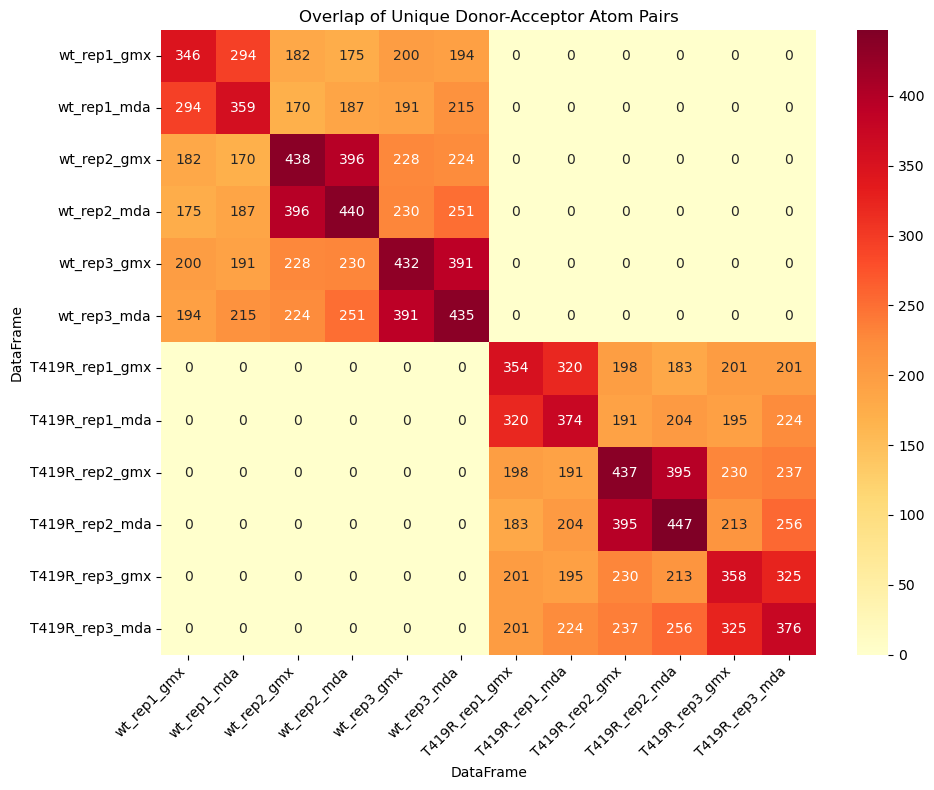

In [91]:
# Combine WT and T419R DataFrames
all_dfs_flat = wt_dfs_flat + T419R_dfs_flat

# Key columns for triplets
key_cols = ['donor', 'acceptor']

# Labels for DataFrames
labels = ['wt_rep1_gmx', 'wt_rep1_mda', 
          'wt_rep2_gmx', 'wt_rep2_mda', 'wt_rep3_gmx', 'wt_rep3_mda',
          'T419R_rep1_gmx', 'T419R_rep1_mda', 
          'T419R_rep2_gmx', 'T419R_rep2_mda', 'T419R_rep3_gmx', 'T419R_rep3_mda']

# Verify lengths match
n_labels = len(labels)
n_dfs = len(all_dfs_flat)
if n_labels != n_dfs:
    raise ValueError(f"Number of labels ({n_labels}) does not match number of DataFrames ({n_dfs})")

# Matrix to store overlap counts
overlap_matrix = np.zeros((n_labels, n_labels))

# Calculate overlaps between each pair of DataFrames
for i in range(n_labels):
    for j in range(n_labels):
        # Get unique triplets from each DataFrame
        df1_triplets = all_dfs_flat[i][key_cols]
        df2_triplets = all_dfs_flat[j][key_cols]
        
        # Find overlapping triplets
        overlap = pd.merge(df1_triplets, df2_triplets, how='inner')
        
        # Store the count of overlapping triplets
        overlap_matrix[i, j] = len(overlap)

# Create heatmap
plt.figure(figsize=(10, 8))  # Adjusted size for more labels
sns.heatmap(overlap_matrix, 
            annot=True, 
            fmt='.0f',  
            cmap='YlOrRd', 
            xticklabels=labels,
            yticklabels=labels)

# Customize the plot
plt.title('Overlap of Unique Donor-Acceptor Atom Pairs')
plt.xlabel('DataFrame')
plt.ylabel('DataFrame')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Adjust layout to prevent label cutoff
plt.tight_layout()

# Show the plot
plt.show()

Verify that there are no common donor-acceptor atom pairs identified between WT and T419R.

In [92]:
# Key columns
key_cols = ['donor', 'acceptor']

# Aggregate unique triplets from wt_dfs_flat
wt_triplets = pd.concat([df[key_cols] for df in wt_dfs_flat], ignore_index=True).drop_duplicates()

# Aggregate unique triplets from T419R_dfs_flat
T419R_triplets = pd.concat([df[key_cols] for df in T419R_dfs_flat], ignore_index=True).drop_duplicates()

# Find overlapping triplets
overlap = pd.merge(wt_triplets, T419R_triplets, how='inner', on=key_cols)

# Report results
if overlap.empty:
    print("No common ['donor', 'hydrogen', 'acceptor'] triplets between WT and T419R DataFrames.")
else:
    print(f"Found {len(overlap)} common triplets:")
    print(overlap)

# Optional: Show number of unique triplets in each group
print(f"Unique WT triplets: {len(wt_triplets)}")
print(f"Unique T419R triplets: {len(T419R_triplets)}")

No common ['donor', 'hydrogen', 'acceptor'] triplets between WT and T419R DataFrames.
Unique WT triplets: 339
Unique T419R triplets: 344


For a less stringent comparison, consider the donor and acceptor residue numbers instead of specific atoms.

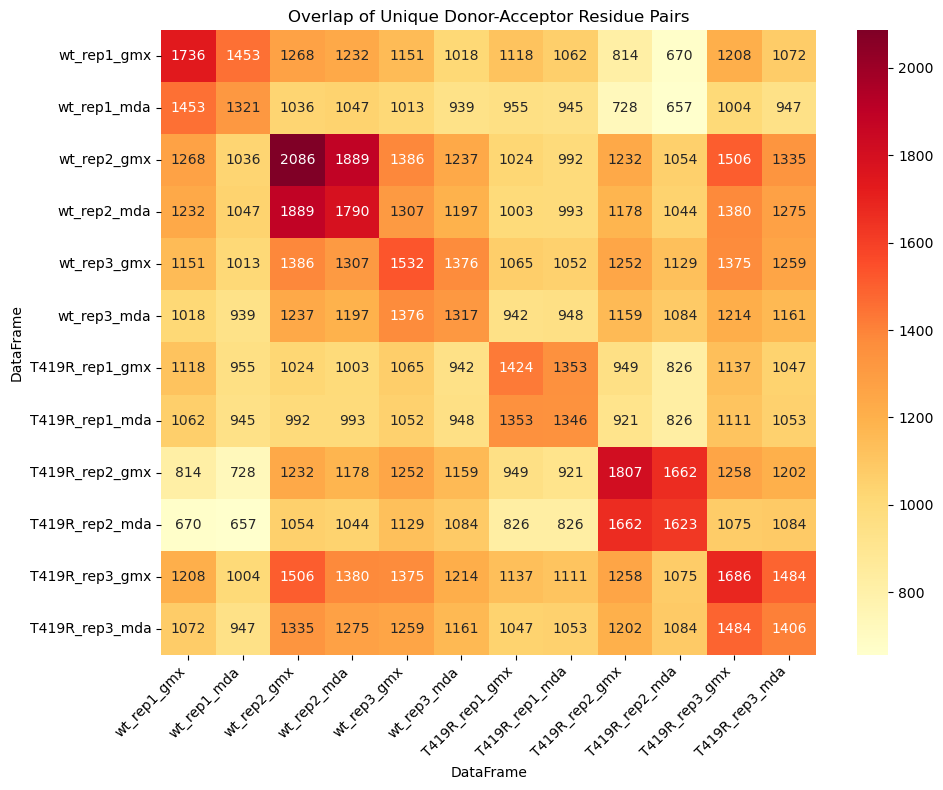

In [93]:
# Combine WT and T419R DataFrames
all_dfs_flat = wt_dfs_flat + T419R_dfs_flat

# Key columns for triplets
key_cols = ['donor_res_num', 'acceptor_res_num']

# Labels for DataFrames
labels = ['wt_rep1_gmx', 'wt_rep1_mda', 
          'wt_rep2_gmx', 'wt_rep2_mda', 'wt_rep3_gmx', 'wt_rep3_mda',
          'T419R_rep1_gmx', 'T419R_rep1_mda', 
          'T419R_rep2_gmx', 'T419R_rep2_mda', 'T419R_rep3_gmx', 'T419R_rep3_mda']

# Verify lengths match
n_labels = len(labels)
n_dfs = len(all_dfs_flat)
if n_labels != n_dfs:
    raise ValueError(f"Number of labels ({n_labels}) does not match number of DataFrames ({n_dfs})")

# Matrix to store overlap counts
overlap_matrix = np.zeros((n_labels, n_labels))

# Calculate overlaps between each pair of DataFrames
for i in range(n_labels):
    for j in range(n_labels):
        # Get unique triplets from each DataFrame
        df2_triplets = all_dfs_flat[j][key_cols]
        df1_triplets = all_dfs_flat[i][key_cols]
        
        # Find overlapping triplets
        overlap = pd.merge(df1_triplets, df2_triplets, how='inner')
        
        # Store the count of overlapping triplets
        overlap_matrix[i, j] = len(overlap)

# Create heatmap
plt.figure(figsize=(10, 8))  # Adjusted size for more labels
sns.heatmap(overlap_matrix, 
            annot=True, 
            fmt='.0f',  
            cmap='YlOrRd', 
            xticklabels=labels,
            yticklabels=labels)

# Customize the plot
plt.title('Overlap of Unique Donor-Acceptor Residue Pairs')
plt.xlabel('DataFrame')
plt.ylabel('DataFrame')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Adjust layout to prevent label cutoff
plt.tight_layout()

# Show the plot
plt.show()

Plot overlap ratios.

[50, 54, 53, 57, 60, 64, 56, 57, 54, 52, 53, 53]


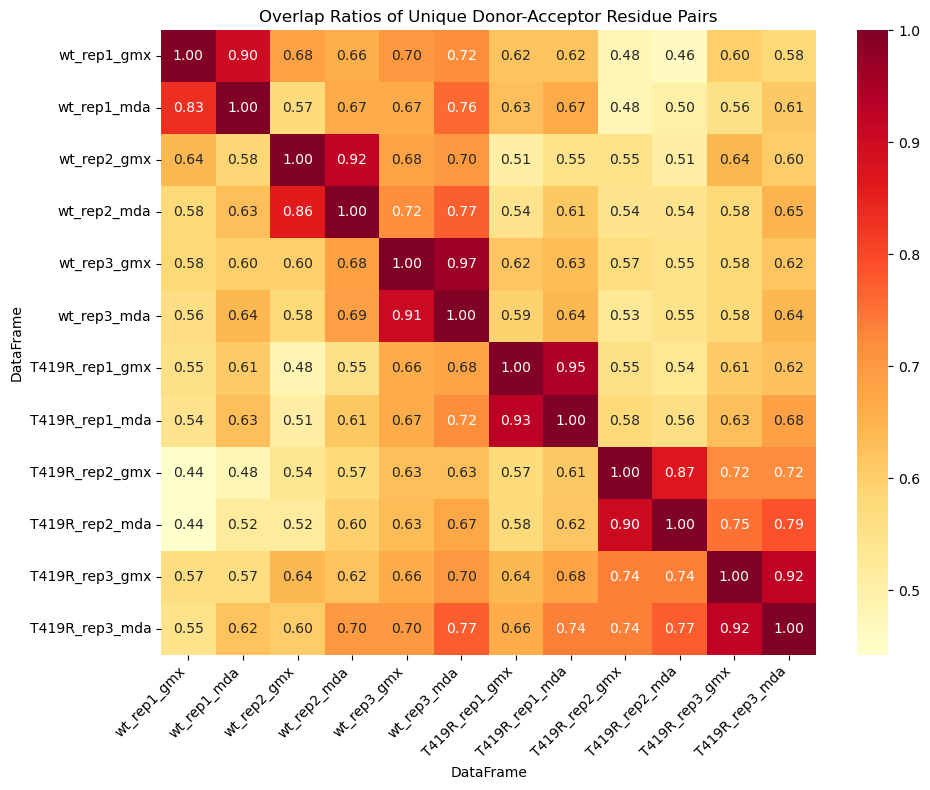

In [94]:
key_cols = ['donor_res_num', 'acceptor_res_num']
total_unique = [len(df[key_cols].drop_duplicates()) for df in all_dfs_flat]

print(total_unique)


# Matrix to store overlap counts
overlap_ratio_matrix = np.zeros((n_labels, n_labels))

# Calculate overlaps between each pair of DataFrames
for i in range(n_labels):
    for j in range(n_labels):
        # Get unique triplets from each DataFrame
        df1_triplets = all_dfs_flat[i][key_cols].drop_duplicates()
        df2_triplets = all_dfs_flat[j][key_cols].drop_duplicates()
        
        # Find overlapping triplets
        overlap = pd.merge(df1_triplets, df2_triplets, how='inner')
        
        
        # Calculate ratio relative to total unique triplets in df[i] (y-axis)
        ratio = len(overlap) / total_unique[i] if total_unique[i] > 0 else 0
        overlap_ratio_matrix[i, j] = ratio

# Create heatmap
plt.figure(figsize=(10, 8))  # Adjusted size for more labels
sns.heatmap(overlap_ratio_matrix, 
            annot=True, 
            fmt='.2f',  
            cmap='YlOrRd', 
            xticklabels=labels,
            yticklabels=labels)

# Customize the plot
plt.title('Overlap Ratios of Unique Donor-Acceptor Residue Pairs')
plt.xlabel('DataFrame')
plt.ylabel('DataFrame')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Adjust layout to prevent label cutoff
plt.tight_layout()

# Show the plot
plt.show()

[149, 134, 159, 154, 155, 147, 157, 151, 150, 136, 150, 138]


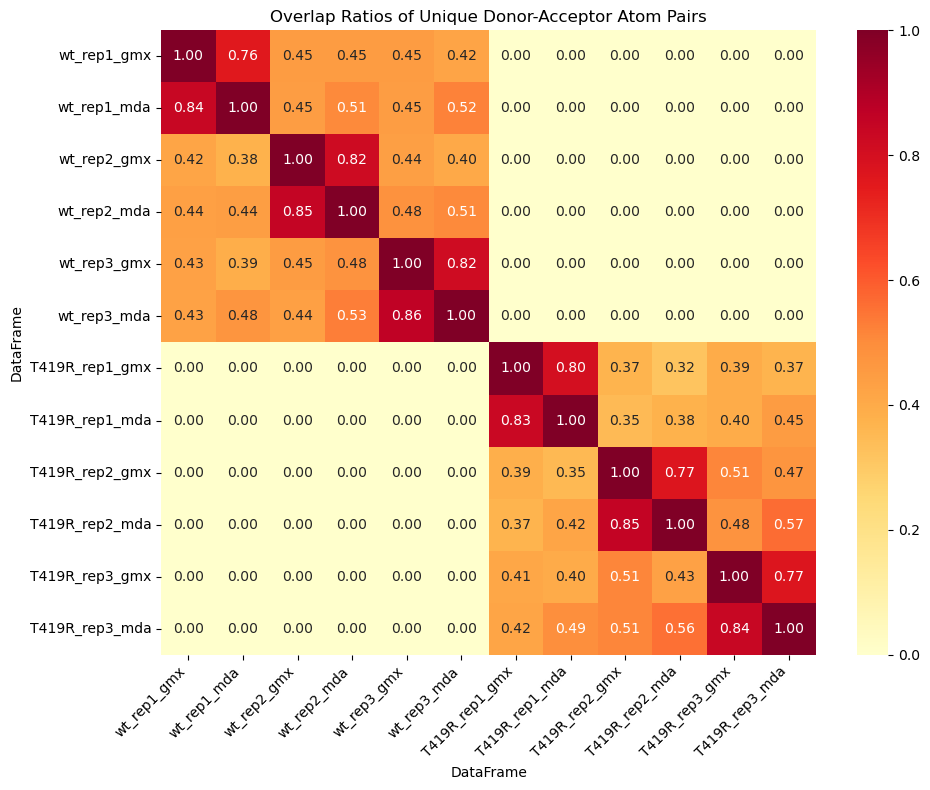

In [95]:
key_cols = ['donor', 'acceptor']
total_unique = [len(df[key_cols].drop_duplicates()) for df in all_dfs_flat]

print(total_unique)


# Matrix to store overlap counts
overlap_ratio_matrix = np.zeros((n_labels, n_labels))

# Calculate overlaps between each pair of DataFrames
for i in range(n_labels):
    for j in range(n_labels):
        # Get unique triplets from each DataFrame
        df1_triplets = all_dfs_flat[i][key_cols].drop_duplicates()
        df2_triplets = all_dfs_flat[j][key_cols].drop_duplicates()
        
        # Find overlapping triplets
        overlap = pd.merge(df1_triplets, df2_triplets, how='inner')
        
        
        # Calculate ratio relative to total unique triplets in df[i] (y-axis)
        ratio = len(overlap) / total_unique[i] if total_unique[i] > 0 else 0
        overlap_ratio_matrix[i, j] = ratio

# Create heatmap
plt.figure(figsize=(10, 8))  # Adjusted size for more labels
sns.heatmap(overlap_ratio_matrix, 
            annot=True, 
            fmt='.2f',  
            cmap='YlOrRd', 
            xticklabels=labels,
            yticklabels=labels)

# Customize the plot
plt.title('Overlap Ratios of Unique Donor-Acceptor Atom Pairs')
plt.xlabel('DataFrame')
plt.ylabel('DataFrame')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

# Adjust layout to prevent label cutoff
plt.tight_layout()

# Show the plot
plt.show()

## Bond distribution

In [96]:
combined_df_wt = pd.concat(wt_dfs_flat)

In [97]:
combined_df_wt.columns

Index(['donor', 'hydrogen', 'acceptor', 'count', 'frame%', 'donor_res_name',
       'donor_res_num', 'donor_atom_name', 'donor_chain', 'acceptor_res_name',
       'acceptor_res_num', 'acceptor_atom_name', 'acceptor_chain',
       'donor_type', 'acceptor_type', 'donor_res_num_adjusted',
       'acceptor_res_num_adjusted', 'donor_section', 'acceptor_section'],
      dtype='object')

In [98]:
combined_df_wt["donor_type"].value_counts()

donor_type
protein    1290
DNA          40
Name: count, dtype: int64

In [99]:
print(combined_df_wt[combined_df_wt["donor_type"] == "protein"]["frame%"].mean())
print(combined_df_wt[combined_df_wt["donor_type"] == "DNA"]["frame%"].mean())

7.381533195486684
0.9965034965034965


As expected, the protein (amino acids) acts as donor in the majority of identified hydrogen bonds and the average number of frames in which these bonds are identified is higher, indicating the positions that lead to them are more stable in time. Therefore, the analysis focuses on the protein as donor and DNA as acceptor in hydrogen bonds.

### WT

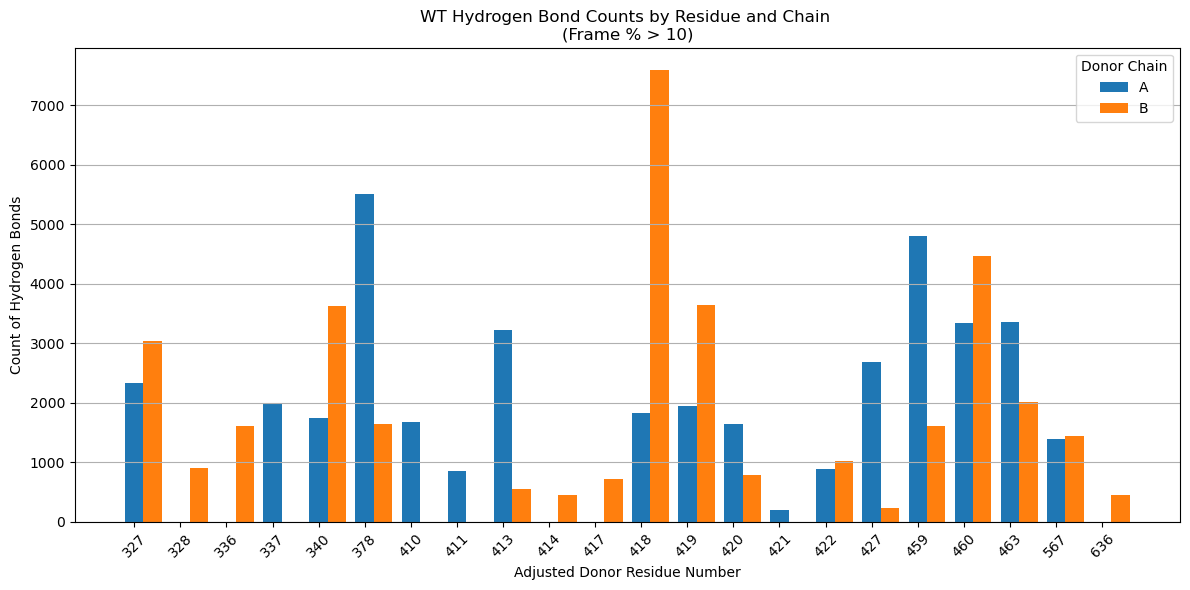

In [100]:
filtered_df = combined_df_wt[combined_df_wt['frame%'] > 10]

# Pivot the data with aggregation (sum) for duplicate entries
pivot_df = pd.pivot_table(filtered_df, 
                         index='donor_res_num_adjusted',
                         columns='donor_chain',
                         values='count',
                         aggfunc='sum',  # Sum counts for duplicate entries
                         fill_value=0)   # Replace NaN with 0

# Create the plot
plt.figure(figsize=(12, 6))

# Get unique acceptor_section values
sections = pivot_df.columns
n_sections = len(sections)

# Set bar width and positions
bar_width = 0.8 / n_sections  # Adjust width based on number of groups
x = np.arange(len(pivot_df.index))  # Positions for each donor residue

# Plot bars for each acceptor_section
for i, section in enumerate(sections):
    plt.bar(x + i * bar_width, 
            pivot_df[section], 
            width=bar_width, 
            label=section,
            align='edge')

# Customize the plot
plt.xlabel('Adjusted Donor Residue Number')
plt.ylabel('Count of Hydrogen Bonds')
plt.title('WT Hydrogen Bond Counts by Residue and Chain \n(Frame % > 10)')
plt.xticks(x + bar_width * (n_sections - 1) / 2, pivot_df.index, rotation=45)
plt.grid(axis = 'y')
plt.legend(title='Donor Chain')
plt.tight_layout()

# Show the plot
plt.show()

Acceptor section. Are the acceptor atoms in the DNA backbone or in the bases?

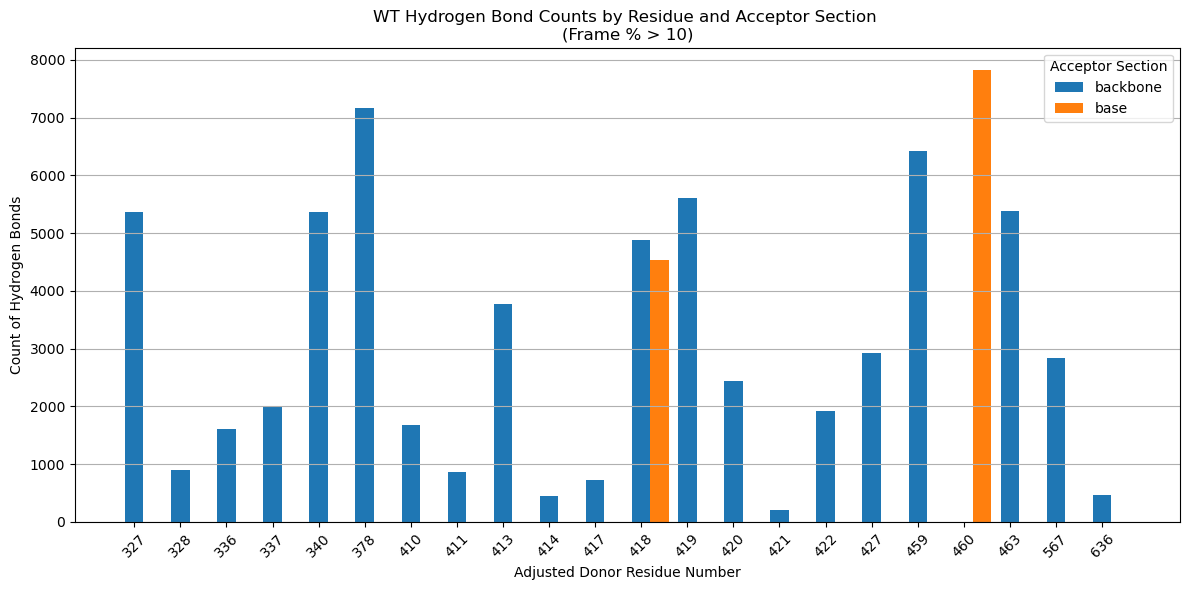

In [101]:
filtered_df = combined_df_wt[combined_df_wt['frame%'] > 10]

# Pivot the data with aggregation (sum) for duplicate entries
pivot_df = pd.pivot_table(filtered_df, 
                         index='donor_res_num_adjusted',
                         columns='acceptor_section',
                         values='count',
                         aggfunc='sum',  # Sum counts for duplicate entries
                         fill_value=0)   # Replace NaN with 0

# Create the plot
plt.figure(figsize=(12, 6))

# Get unique acceptor_section values
sections = pivot_df.columns
n_sections = len(sections)

# Set bar width and positions
bar_width = 0.8 / n_sections  # Adjust width based on number of groups
x = np.arange(len(pivot_df.index))  # Positions for each donor residue

# Plot bars for each acceptor_section
for i, section in enumerate(sections):
    plt.bar(x + i * bar_width, 
            pivot_df[section], 
            width=bar_width, 
            label=section,
            align='edge')

# Customize the plot
plt.xlabel('Adjusted Donor Residue Number')
plt.ylabel('Count of Hydrogen Bonds')
plt.title('WT Hydrogen Bond Counts by Residue and Acceptor Section \n(Frame % > 10)')
plt.xticks(x + bar_width * (n_sections - 1) / 2, pivot_df.index, rotation=45)
plt.grid(axis = 'y')
plt.legend(title='Acceptor Section')
plt.tight_layout()

# Show the plot
plt.show()

#### Summary tables
For 3 replicates and 2 methods, a threshold of count > 600 is equivalent to > 10%.

In [102]:
occ_th = 100 * len(wt_dfs) * len(wt_dfs[0])
occ_th

600

In [103]:
total_frames_wt = 1000 * len(wt_dfs) * len(wt_dfs[0]) # len(wt_dfs[0]) is =2, the number of methods (gmx and mda)
total_frames_wt

6000

**Monomer A**

In [104]:
group_columns = combined_df_wt.columns.difference(["frame%", "count", "hydrogen"])
wt_count = combined_df_wt.groupby(list(group_columns))['count'].sum().reset_index()

wt_count.sort_values("count", ascending=False).head()

,acceptor,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num,acceptor_res_num_adjusted,acceptor_section,acceptor_type,donor,donor_atom_name,donor_chain,donor_res_name,donor_res_num,donor_res_num_adjusted,donor_section,donor_type,count
40,19049,OP2,C,DT,8,8,backbone,DNA,5365,OG,A,SER,324,459,DBD,protein,4800
37,19048,OP1,C,DT,8,8,backbone,DNA,4104,NH1,A,ARG,243,378,DBD,protein,4438
226,19827,O4,D,DT,9,9,base,DNA,14791,ND2,B,ASN,325,460,DBD,protein,2800
69,19172,OP1,C,DC,12,12,backbone,DNA,12629,OG1,B,THR,192,327,DBD,protein,2710
30,19016,OP1,C,DT,7,7,backbone,DNA,4874,OG1,A,THR,292,427,DBD,protein,2690


In [105]:
wt_count[(wt_count['donor_chain'] == 'A') & (wt_count["count"] > occ_th)].shape

(20, 17)

In [106]:
summary_cols = wt_count.columns.difference(["acceptor", "donor", "hydrogen", "acceptor_type", "donor_type", "donor_chain", "donor_res_num", "acceptor_res_num"])
wt_count[(wt_count['donor_chain'] == 'A') & (wt_count["count"] > occ_th)].sort_values('count', ascending=False)[summary_cols]

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section
40,OP2,C,DT,8,backbone,4800,OG,SER,459,DBD
37,OP1,C,DT,8,backbone,4438,NH1,ARG,378,DBD
30,OP1,C,DT,7,backbone,2690,OG1,THR,427,DBD
47,OP1,C,DT,9,backbone,2560,NZ,LYS,413,DBD
41,OP2,C,DT,8,backbone,2375,NE2,GLN,463,DBD
48,OP2,C,DT,9,backbone,1999,OG1,THR,337,DBD
245,OP2,D,DG,12,backbone,1930,OG1,THR,327,DBD
52,O4,C,DT,9,base,1810,ND2,ASN,460,DBD
252,OP1,D,DG,13,backbone,1788,NZ,LYS,567,LD
45,OP1,C,DT,9,backbone,1712,NZ,LYS,410,DBD


In [107]:
wt_monoA_summary = wt_count[(wt_count['donor_chain'] == 'A') & (wt_count["count"] > occ_th)][summary_cols]
wt_monoA_summary['occupancy'] = round(wt_monoA_summary['count'] / total_frames_wt, 2)
wt_monoA_summary.sort_values("occupancy", ascending=False).head()

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section,occupancy
40,OP2,C,DT,8,backbone,4800,OG,SER,459,DBD,0.80
37,OP1,C,DT,8,backbone,4438,NH1,ARG,378,DBD,0.74
30,OP1,C,DT,7,backbone,2690,OG1,THR,427,DBD,0.45
47,OP1,C,DT,9,backbone,2560,NZ,LYS,413,DBD,0.43
41,OP2,C,DT,8,backbone,2375,NE2,GLN,463,DBD,0.40


**Monomer B**

In [108]:
wt_count[(wt_count['donor_chain'] == 'B') & (wt_count["count"] > occ_th)].shape

(26, 17)

In [109]:
summary_cols = wt_count.columns.difference(["acceptor", "donor", "hydrogen", "acceptor_type", "donor_type", "donor_chain", "donor_res_num", "acceptor_res_num"])
wt_count[(wt_count['donor_chain'] == 'B') & (wt_count["count"] > occ_th)].sort_values('count', ascending=False)[summary_cols]

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section
226,O4,D,DT,9,base,2800,ND2,ASN,460,DBD
69,OP1,C,DC,12,backbone,2710,OG1,THR,327,DBD
77,OP1,C,DG,13,backbone,2140,NZ,LYS,567,LD
74,OP2,C,DC,12,backbone,1893,NZ,LYS,336,DBD
212,OP2,D,DT,8,backbone,1817,NE2,GLN,463,DBD
211,OP2,D,DT,8,backbone,1633,OG,SER,459,DBD
138,OP1,C,DA,21,backbone,1576,OG1,THR,419,DBD
104,O2,C,DT,18,base,1439,NH1,ARG,418,DBD
162,N3,D,DA,6,base,1381,NH1,ARG,418,DBD
105,O2,C,DT,18,base,1332,NH2,ARG,418,DBD


In [110]:
wt_monoB_summary = wt_count[(wt_count['donor_chain'] == 'B') & (wt_count["count"] > occ_th)][summary_cols]
wt_monoB_summary['occupancy'] = round(wt_monoB_summary['count'] / total_frames_wt, 2)
wt_monoB_summary.sort_values("occupancy", ascending=False).head()

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section,occupancy
226,O4,D,DT,9,base,2800,ND2,ASN,460,DBD,0.47
69,OP1,C,DC,12,backbone,2710,OG1,THR,327,DBD,0.45
77,OP1,C,DG,13,backbone,2140,NZ,LYS,567,LD,0.36
74,OP2,C,DC,12,backbone,1893,NZ,LYS,336,DBD,0.32
212,OP2,D,DT,8,backbone,1817,NE2,GLN,463,DBD,0.30


In [111]:
wt_summary = pd.concat([wt_monoA_summary, wt_monoB_summary],keys= ['Monomer A', 'Monomer B'])

In [112]:
wt_summary

acceptor_atom_name acceptor_chain acceptor_res_name  \
Monomer A 28                 O4'              C                DG   
          30                 OP1              C                DT   
          32                 OP2              C                DT   
          37                 OP1              C                DT   
          38                 OP2              C                DT   
          40                 OP2              C                DT   
          41                 OP2              C                DT   
          44                 O3'              C                DT   
          45                 OP1              C                DT   
          47                 OP1              C                DT   
          48                 OP2              C                DT   
          50                 OP2              C                DT   
          52                  O4              C                DT   
          236                OP1              D                DC   
          245                OP2              D                DG   
          252                OP1              D                DG   
          254                OP2              D                DG   
          266                 O6              D                DG   
          296                OP1              D                DG   
          320                O3'              D                DG   
Monomer B 62                 OP1              C                DC   
          63                 OP1              C                DC   
          64                 OP2              C                DC   
          69                 OP1              C                DC   
          74                 OP2              C                DC   
          77                 OP1              C                DG   
          87                 OP1              C                DG   
          90                 OP2              C                DG   
          93                  N7              C                DG   
          94                  O6              C                DG   
          104                 O2              C                DT   
          105                 O2              C                DT   
          138                OP1              C                DA   
          162                 N3              D                DA   
          167                OP1              D                DT   
          168                OP1              D                DT   
          169                OP1              D                DT   
          170                OP1              D                DT   
          172                OP1              D                DT   
          200                OP1              D                DT   
          201                OP1              D                DT   
          211                OP2              D                DT   
          212                OP2              D                DT   
          219                 O4              D                DT   
          222                OP1              D                DT   
          226                 O4              D                DT   

               acceptor_res_num_adjusted acceptor_section  count  \
Monomer A 28                           6         backbone    630   
          30                           7         backbone   2690   
          32                           7         backbone   1238   
          37                           8         backbone   4438   
          38                           8         backbone   1114   
          40                           8         backbone   4800   
          41                           8         backbone   2375   
          44                           8         backbone   1303   
          45                           9         backbone   1712   
          47                           9         backbone   2560   
          48          

In [113]:
wt_summary.to_csv('wt_summary.csv')

### T419R

Find unique pairs of donor-acceptor atoms and sum their counts across replicates and methods. The hydrogen atom number is not taken into account to consider it as the "same bond".

In [114]:
combined_df_T419R = pd.concat(T419R_dfs_flat)

In [115]:
group_columns = combined_df_T419R.columns.difference(["frame%", "count", "hydrogen"])
T419R_count = combined_df_T419R.groupby(list(group_columns))['count'].sum().reset_index()

T419R_count.sort_values("count", ascending=False).head()

,acceptor,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num,acceptor_res_num_adjusted,acceptor_section,acceptor_type,donor,donor_atom_name,donor_chain,donor_res_name,donor_res_num,donor_res_num_adjusted,donor_section,donor_type,count
238,19847,O4,D,DT,9,9,base,DNA,14811,ND2,B,ASN,325,460,DBD,protein,4966
213,19796,OP2,D,DT,8,8,backbone,DNA,14855,NE2,B,GLN,328,463,DBD,protein,4537
212,19796,OP2,D,DT,8,8,backbone,DNA,14798,OG,B,SER,324,459,DBD,protein,4442
84,19193,OP2,C,DC,12,12,backbone,DNA,12799,NZ,B,LYS,201,336,DBD,protein,4338
80,19192,OP1,C,DC,12,12,backbone,DNA,12639,OG1,B,THR,192,327,DBD,protein,3998


In [116]:
T419R_count.shape

(344, 17)

Comparison between monomers A and B.

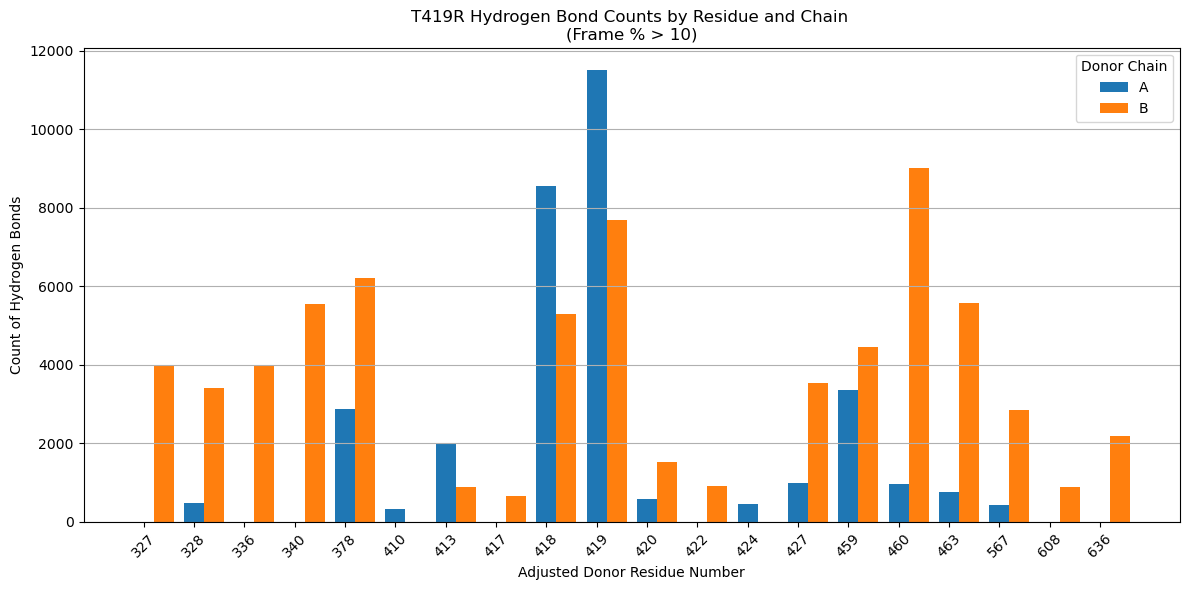

In [117]:
filtered_df = combined_df_T419R[combined_df_T419R['frame%'] > 10]

# Pivot the data with aggregation (sum) for duplicate entries
pivot_df = pd.pivot_table(filtered_df, 
                         index='donor_res_num_adjusted',
                         columns='donor_chain',
                         values='count',
                         aggfunc='sum',  # Sum counts for duplicate entries
                         fill_value=0)   # Replace NaN with 0

# Create the plot
plt.figure(figsize=(12, 6))

# Get unique acceptor_section values
sections = pivot_df.columns
n_sections = len(sections)

# Set bar width and positions
bar_width = 0.8 / n_sections  # Adjust width based on number of groups
x = np.arange(len(pivot_df.index))  # Positions for each donor residue

# Plot bars for each acceptor_section
for i, section in enumerate(sections):
    plt.bar(x + i * bar_width, 
            pivot_df[section], 
            width=bar_width, 
            label=section,
            align='edge')

# Customize the plot
plt.xlabel('Adjusted Donor Residue Number')
plt.ylabel('Count of Hydrogen Bonds')
plt.title('T419R Hydrogen Bond Counts by Residue and Chain \n(Frame % > 10)')
plt.xticks(x + bar_width * (n_sections - 1) / 2, pivot_df.index, rotation=45)
plt.grid(axis = 'y')
plt.legend(title='Donor Chain')
plt.tight_layout()

# Show the plot
plt.show()

Acceptor section. Are the acceptor atoms in the DNA backbone or in the bases?

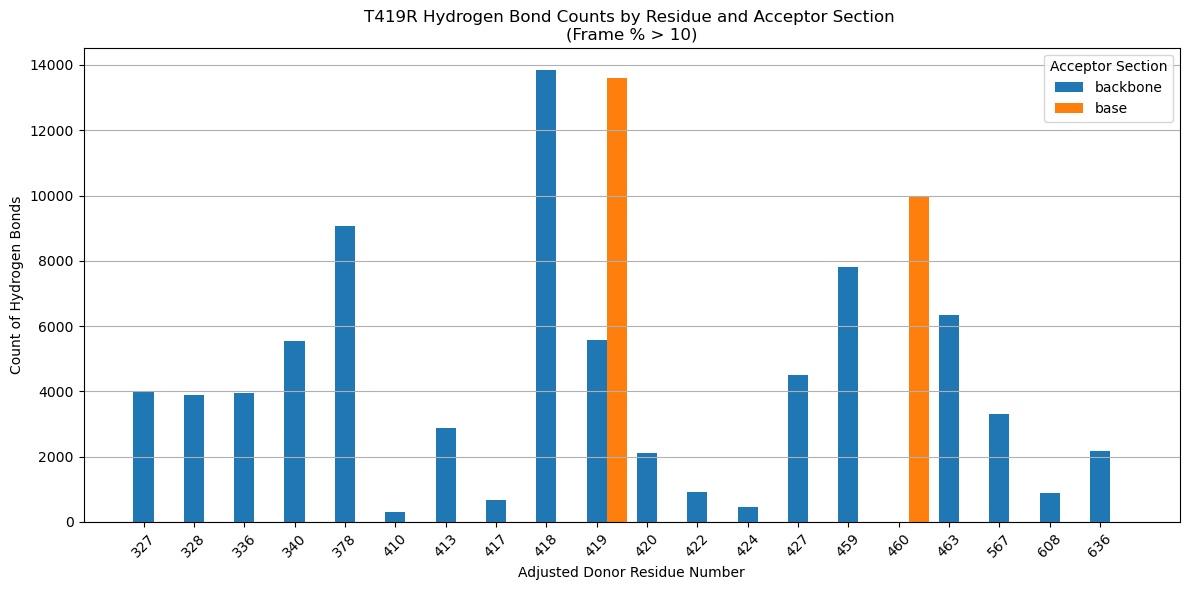

In [118]:
filtered_df = combined_df_T419R[combined_df_T419R['frame%'] > 10]

# Pivot the data with aggregation (sum) for duplicate entries
pivot_df = pd.pivot_table(filtered_df, 
                         index='donor_res_num_adjusted',
                         columns='acceptor_section',
                         values='count',
                         aggfunc='sum',  # Sum counts for duplicate entries
                         fill_value=0)   # Replace NaN with 0

# Create the plot
plt.figure(figsize=(12, 6))

# Get unique acceptor_section values
sections = pivot_df.columns
n_sections = len(sections)

# Set bar width and positions
bar_width = 0.8 / n_sections  # Adjust width based on number of groups
x = np.arange(len(pivot_df.index))  # Positions for each donor residue

# Plot bars for each acceptor_section
for i, section in enumerate(sections):
    plt.bar(x + i * bar_width, 
            pivot_df[section], 
            width=bar_width, 
            label=section,
            align='edge')

# Customize the plot
plt.xlabel('Adjusted Donor Residue Number')
plt.ylabel('Count of Hydrogen Bonds')
plt.title('T419R Hydrogen Bond Counts by Residue and Acceptor Section \n(Frame % > 10)')
plt.xticks(x + bar_width * (n_sections - 1) / 2, pivot_df.index, rotation=45)
plt.grid(axis = 'y')
plt.legend(title='Acceptor Section')
plt.tight_layout()

# Show the plot
plt.show()

#### Summary tables
For 3 replicates and 2 methods, a threshold of count > 600 is equivalent to > 10%.

In [119]:
occ_th = 100 * len(wt_dfs) * len(wt_dfs[0])
occ_th

600

In [120]:
total_frames_T419R = 1000 * len(T419R_dfs) * len(T419R_dfs[0])
total_frames_T419R

6000

**Monomer A**

In [121]:
T419R_count[(T419R_count['donor_chain'] == 'A') & (T419R_count["count"] > occ_th)].shape

(21, 17)

In [122]:
summary_cols = T419R_count.columns.difference(["acceptor", "donor", "hydrogen", "acceptor_type", "donor_type", "donor_chain", "donor_res_num", "acceptor_res_num"])
T419R_count[(T419R_count['donor_chain'] == 'A') & (T419R_count["count"] > occ_th)].sort_values('count', ascending=False)[summary_cols]

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section
293,O2,D,DT,19,base,3674,NH2,ARG,419,DBD
58,OP2,C,DT,8,backbone,3401,OG,SER,459,DBD
297,OP1,D,DG,20,backbone,2662,NE,ARG,418,DBD
292,O2,D,DT,19,base,2239,NH1,ARG,419,DBD
56,OP2,C,DT,8,backbone,2216,NH1,ARG,378,DBD
299,OP1,D,DG,20,backbone,1994,NH2,ARG,418,DBD
66,OP1,C,DT,9,backbone,1947,NZ,LYS,413,DBD
260,OP1,D,DG,13,backbone,1207,NZ,LYS,567,LD
304,OP2,D,DG,20,backbone,1100,NH2,ARG,418,DBD
314,N3,D,DG,20,base,1040,NH1,ARG,419,DBD


In [123]:
T419R_monoA_summary = T419R_count[(T419R_count['donor_chain'] == 'A') & (T419R_count["count"] > occ_th)][summary_cols]
T419R_monoA_summary['occupancy'] = round(T419R_monoA_summary['count'] / total_frames_T419R, 2)
T419R_monoA_summary.sort_values("occupancy", ascending=False).head()

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section,occupancy
293,O2,D,DT,19,base,3674,NH2,ARG,419,DBD,0.61
58,OP2,C,DT,8,backbone,3401,OG,SER,459,DBD,0.57
297,OP1,D,DG,20,backbone,2662,NE,ARG,418,DBD,0.44
56,OP2,C,DT,8,backbone,2216,NH1,ARG,378,DBD,0.37
292,O2,D,DT,19,base,2239,NH1,ARG,419,DBD,0.37


**Monomer B**

In [124]:
T419R_count[(T419R_count['donor_chain'] == 'B') & (T419R_count["count"] > occ_th)].shape

(32, 17)

In [125]:
summary_cols = T419R_count.columns.difference(["acceptor", "donor", "hydrogen", "acceptor_type", "donor_type", "donor_chain", "donor_res_num", "acceptor_res_num"])
T419R_count[(T419R_count['donor_chain'] == 'B') & (T419R_count["count"] > occ_th)].sort_values('count', ascending=False)[summary_cols]

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section
238,O4,D,DT,9,base,4966,ND2,ASN,460,DBD
213,OP2,D,DT,8,backbone,4537,NE2,GLN,463,DBD
212,OP2,D,DT,8,backbone,4442,OG,SER,459,DBD
84,OP2,C,DC,12,backbone,4338,NZ,LYS,336,DBD
80,OP1,C,DC,12,backbone,3998,OG1,THR,327,DBD
81,OP1,C,DC,12,backbone,3497,NE2,HIE,328,DBD
202,OP1,D,DT,8,backbone,3236,NH1,ARG,378,DBD
103,O6,C,DG,14,base,3133,ND2,ASN,460,DBD
88,OP1,C,DG,13,backbone,3125,NZ,LYS,567,LD
115,O2,C,DT,18,base,2776,NH2,ARG,419,DBD


In [126]:
T419R_monoB_summary = T419R_count[(T419R_count['donor_chain'] == 'B') & (T419R_count["count"] > occ_th)][summary_cols]
T419R_monoB_summary['occupancy'] = round(T419R_monoB_summary['count'] / total_frames_T419R, 2)
T419R_monoB_summary.sort_values("occupancy", ascending=False).head()

,acceptor_atom_name,acceptor_chain,acceptor_res_name,acceptor_res_num_adjusted,acceptor_section,count,donor_atom_name,donor_res_name,donor_res_num_adjusted,donor_section,occupancy
238,O4,D,DT,9,base,4966,ND2,ASN,460,DBD,0.83
213,OP2,D,DT,8,backbone,4537,NE2,GLN,463,DBD,0.76
212,OP2,D,DT,8,backbone,4442,OG,SER,459,DBD,0.74
84,OP2,C,DC,12,backbone,4338,NZ,LYS,336,DBD,0.72
80,OP1,C,DC,12,backbone,3998,OG1,THR,327,DBD,0.67


In [127]:
T419R_summary = pd.concat([T419R_monoA_summary, T419R_monoB_summary],keys= ['Monomer A', 'Monomer B'])

In [128]:
T419R_summary

acceptor_atom_name acceptor_chain acceptor_res_name  \
Monomer A 12                  N3              C                DA   
          24                 O3'              C                DG   
          32                 OP1              C                DT   
          37                 OP1              C                DT   
          56                 OP2              C                DT   
          57                 OP2              C                DT   
          58                 OP2              C                DT   
          66                 OP1              C                DT   
          67                 OP2              C                DT   
          69                  O4              C                DT   
          260                OP1              D                DG   
          288                OP1              D                DT   
          292                 O2              D                DT   
          293                 O2              D                DT   
          297                OP1              D                DG   
          299                OP1              D                DG   
          304                OP2              D                DG   
          309                O4'              D                DG   
          314                 N3              D                DG   
          320                OP1              D                DT   
          329                OP2              D                DT   
Monomer B 74                 OP1              C                DC   
          75                 OP1              C                DC   
          76                 OP2              C                DC   
          80                 OP1              C                DC   
          81                 OP1              C                DC   
          84                 OP2              C                DC   
          88                 OP1              C                DG   
          95                 OP1              C                DG   
          98                 OP2              C                DG   
          102                 N7              C                DG   
          103                 O6              C                DG   
          114                 O2              C                DT   
          115                 O2              C                DT   
          140                OP1              C                DC   
          145                OP1              C                DC   
          147                OP2              C                DC   
          149                OP2              C                DC   
          160                OP1              C                DA   
          162                OP2              C                DA   
          163                OP2              C                DA   
          186                OP1              D                DT   
          189                OP2              D                DT   
          190                OP2              D                DT   
          202                OP1              D                DT   
          208                OP1              D                DT   
          209                OP2              D                DT   
          210                OP2              D                DT   
          212                OP2              D                DT   
          213                OP2              D                DT   
          226                OP1              D                DT   
          229                OP1              D                DT   
          238                 O4              D                DT   

               acceptor_res_num_adjusted acceptor_section  count  \
Monomer A 12                           5             base    741   
          24                           6         backbone    982   
          32                           7         backbone    996   
          37   

In [129]:
T419R_summary.sort_values("donor_res_num_adjusted").to_csv('T419R_summary.csv')

## Comparison T419R vs WT

### Bond distribution

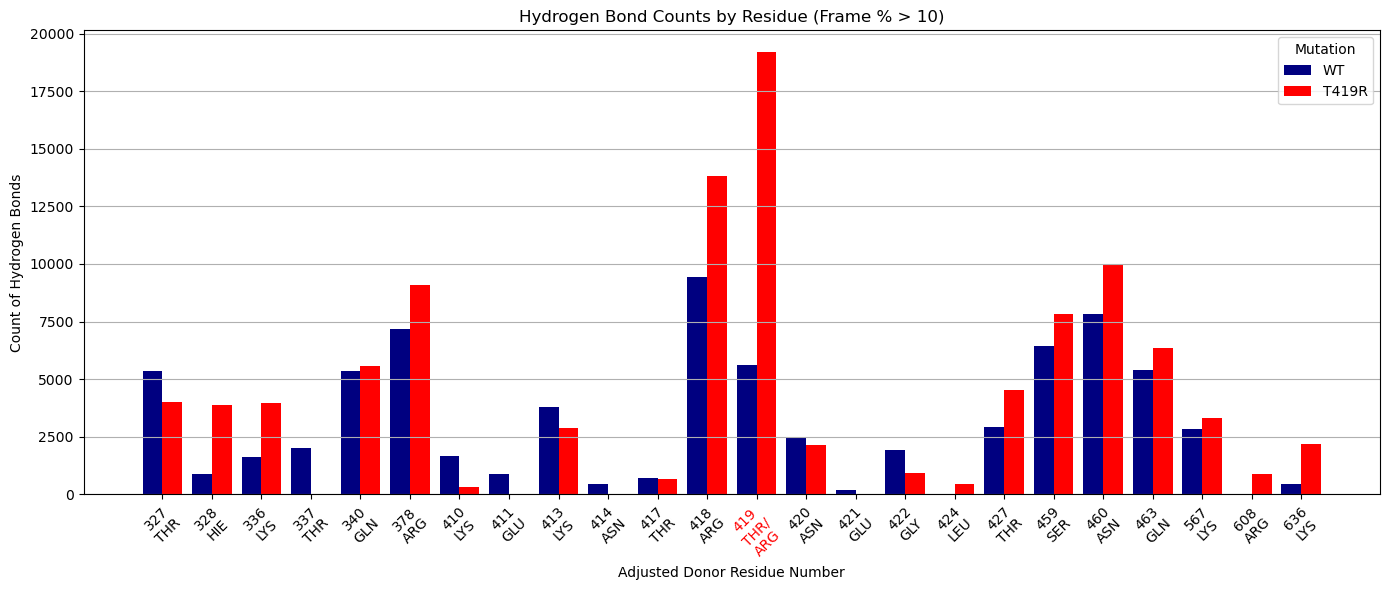

In [130]:
# Filter data for frame% > 10
filtered_df_T419R = combined_df_T419R[combined_df_T419R['frame%'] > 10]
filtered_df_wt = combined_df_wt[combined_df_wt['frame%'] > 10]

# Pivot the data to aggregate counts by donor_res_num_adjusted (no donor_chain)
pivot_df_T419R = pd.pivot_table(filtered_df_T419R, 
                                index='donor_res_num_adjusted',
                                values='count',
                                aggfunc='sum',  # Sum counts for duplicates
                                fill_value=0)   # Replace NaN with 0

pivot_df_wt = pd.pivot_table(filtered_df_wt, 
                             index='donor_res_num_adjusted',
                             values='count',
                             aggfunc='sum',  # Sum counts for duplicates
                             fill_value=0)   # Replace NaN with 0

# Align indices by taking the union of residue numbers
all_residues = sorted(set(pivot_df_T419R.index).union(set(pivot_df_wt.index)))
pivot_df_T419R = pivot_df_T419R.reindex(all_residues, fill_value=0)
pivot_df_wt = pivot_df_wt.reindex(all_residues, fill_value=0)

combined_df = pd.concat([filtered_df_wt, filtered_df_T419R], ignore_index=True)

res_name_map = (combined_df
    .drop_duplicates(subset='donor_res_num_adjusted')
    .set_index('donor_res_num_adjusted')['donor_res_name']
    .reindex(all_residues))

# x-axis labels
x_labels = [
    f"{num}\n{'THR/\nARG' if num == 419 else res_name_map.get(num, '')}"
    for num in all_residues
]


# Create the plot
plt.figure(figsize=(14, 6))

# Set bar width and positions
bar_width = 0.4  # Two bars (T419R and WT)
x = np.arange(len(all_residues))  # Positions for each donor residue

# Plot bars for T419R and WT
plt.bar(x - bar_width/2, 
        pivot_df_wt['count'], 
        width=bar_width, 
        color='navy',
        label='WT')
plt.bar(x + bar_width/2, 
        pivot_df_T419R['count'], 
        width=bar_width, 
        color='red',
        label='T419R')

# Customize the plot
plt.xlabel('Adjusted Donor Residue Number')
plt.ylabel('Count of Hydrogen Bonds')
plt.title('Hydrogen Bond Counts by Residue (Frame % > 10)')
plt.xticks(x, x_labels, rotation=45)
plt.grid(axis='y')
plt.legend(title='Mutation')
plt.tight_layout()

# Highlight mutated residue
mut_index = all_residues.index(419)
ax = plt.gca()  # get current axes
tick_labels = ax.get_xticklabels()
tick_labels[mut_index].set_color('red')

plt.show()

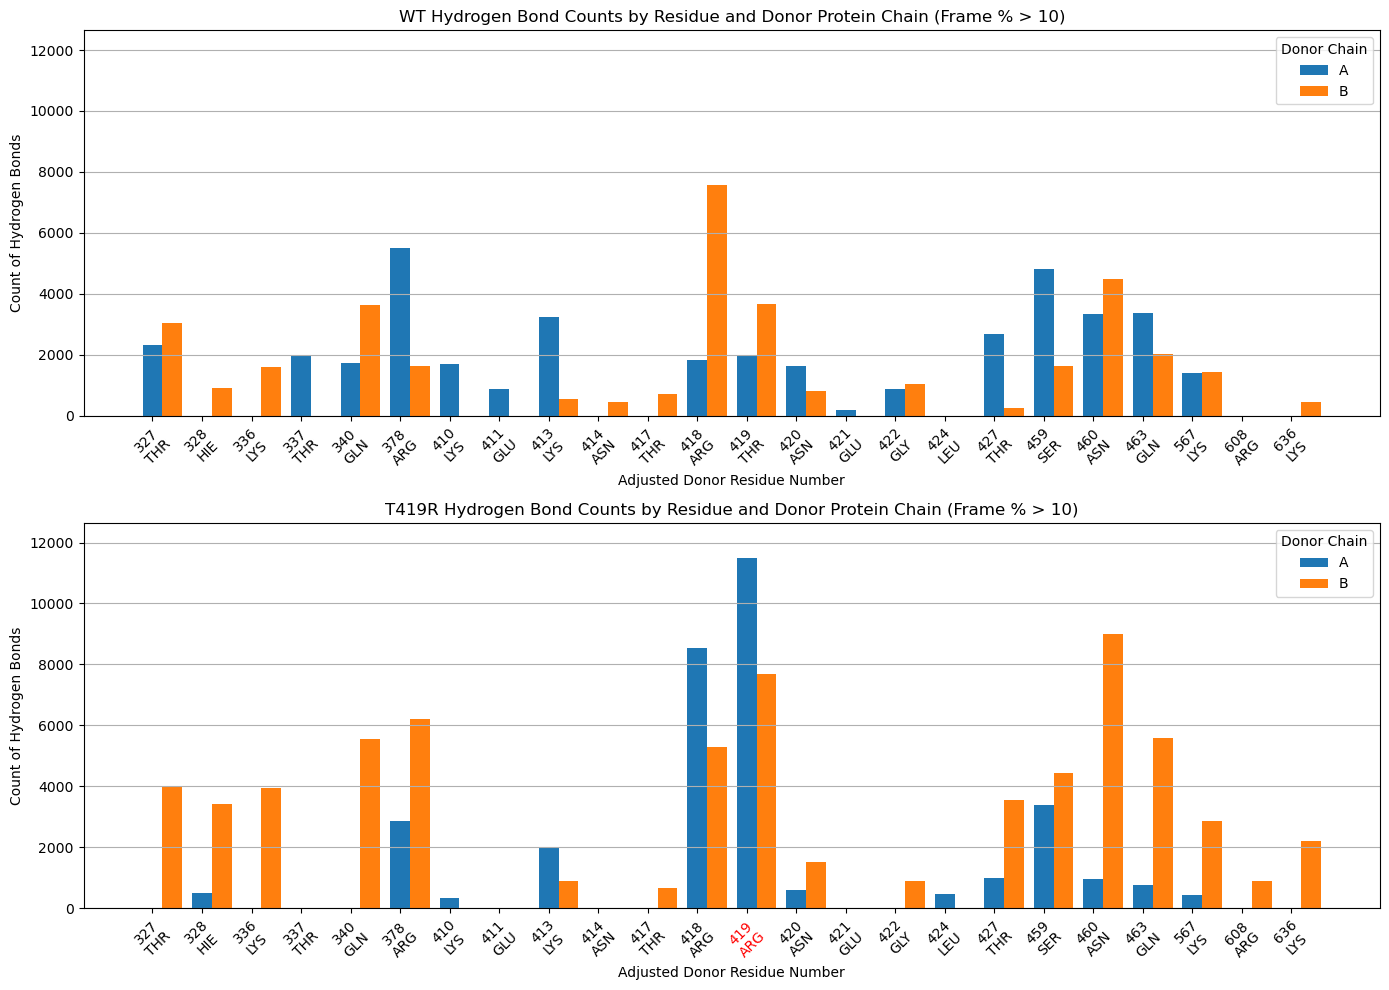

In [131]:
# Filter data for frame% > 10
filtered_df_wt = combined_df_wt[combined_df_wt['frame%'] > 10]
filtered_df_T419R = combined_df_T419R[combined_df_T419R['frame%'] > 10]

# Pivot the data with aggregation (sum) for duplicate entries
pivot_df_wt = pd.pivot_table(filtered_df_wt, 
                             index='donor_res_num_adjusted',
                             columns='donor_chain',
                             values='count',
                             aggfunc='sum',
                             fill_value=0)

pivot_df_T419R = pd.pivot_table(filtered_df_T419R, 
                                index='donor_res_num_adjusted',
                                columns='donor_chain',
                                values='count',
                                aggfunc='sum',
                                fill_value=0)

# Align indices by taking the union of residue numbers
all_residues = sorted(set(pivot_df_wt.index).union(set(pivot_df_T419R.index)))
pivot_df_wt = pivot_df_wt.reindex(all_residues, fill_value=0)
pivot_df_T419R = pivot_df_T419R.reindex(all_residues, fill_value=0)

# Create residue name mapping
combined_df = pd.concat([filtered_df_wt, filtered_df_T419R], ignore_index=True)
res_name_map = (combined_df
                .drop_duplicates(subset='donor_res_num_adjusted')
                .set_index('donor_res_num_adjusted')['donor_res_name']
                .reindex(all_residues)
                .fillna('Unknown'))


# Calculate joint y-axis limits
y_max = max(pivot_df_wt.values.max(), pivot_df_T419R.values.max())
y_min = min(pivot_df_wt.values.min(), pivot_df_T419R.values.min())
y_limits = [y_min, y_max * 1.1]  # Add 10% padding to max

# subplots (2 rows, 1 column)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))

# Data for looping
datasets = [
    {'pivot_df': pivot_df_wt, 'ax': ax1, 'title': 'WT Hydrogen Bond Counts by Residue and Donor Protein Chain (Frame % > 10)'},
    {'pivot_df': pivot_df_T419R, 'ax': ax2, 'title': 'T419R Hydrogen Bond Counts by Residue and Donor Protein Chain (Frame % > 10)'}
]

# Plot
x = np.arange(len(all_residues))
for dataset in datasets:
    pivot_df = dataset['pivot_df']
    ax = dataset['ax']
    sections = pivot_df.columns
    n_sections = len(sections)
    bar_width = 0.8 / n_sections

    for i, section in enumerate(sections):
        ax.bar(x + i * bar_width, 
               pivot_df[section], 
               width=bar_width, 
               label=section,
               align='edge')
    
    ax.set_ylabel('Count of Hydrogen Bonds')
    ax.set_xlabel('Adjusted Donor Residue Number')
    ax.set_title(dataset['title'])
    ax.set_xticks(x + bar_width * (n_sections - 1) / 2)
    x_labels = [
        f"{num}\n{'ARG' if (ax == ax2 and num == 419) else res_name_map[num]}"
        for num in all_residues
    ]
    if ax == ax2:
        mut_index = all_residues.index(419)
        tick_labels = ax.get_xticklabels()
        tick_labels[mut_index].set_color('red')
    ax.set_xticklabels(x_labels, rotation=45)
    ax.set_ylim(y_limits)
    ax.grid(axis='y')
    ax.legend(title='Donor Chain')

plt.tight_layout()
plt.show()

### Protein as donor

**Frame %**

Text(0.5, 1.0, 'WT 419 Hydrogen Bond Frame % Distribution')

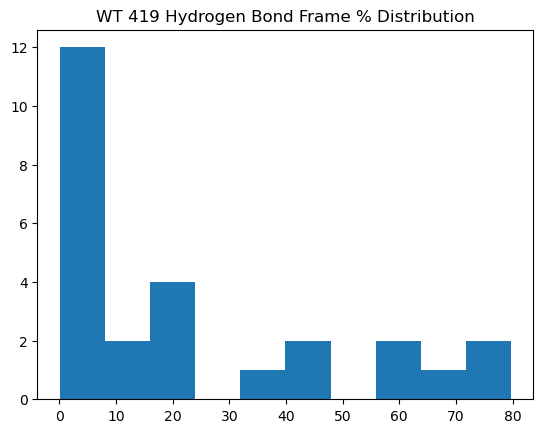

In [132]:
filtered_df = combined_df_wt[combined_df_wt['donor_res_num_adjusted'] == 419]
plt.hist(filtered_df['frame%'])
plt.title('WT 419 Hydrogen Bond Frame % Distribution')

Text(0.5, 1.0, 'T419R 419 Hydrogen Bond Frame % Distribution')

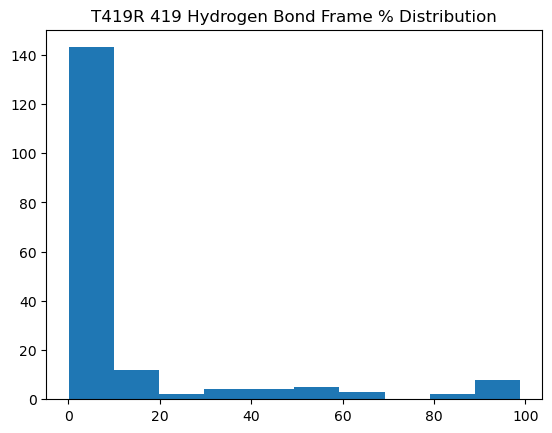

In [133]:
filtered_df = combined_df_T419R[combined_df_T419R['donor_res_num_adjusted'] == 419]
plt.hist(filtered_df['frame%'])
plt.title('T419R 419 Hydrogen Bond Frame % Distribution')

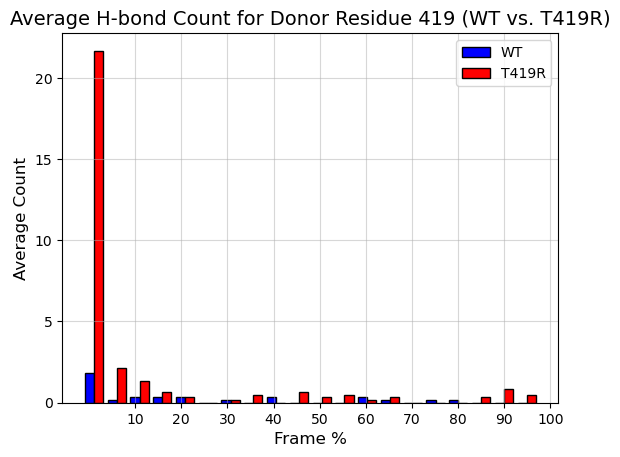

In [137]:
# Filter data
filtered_df_T419R = combined_df_T419R[combined_df_T419R['donor_res_num_adjusted'] == 419]
filtered_df_wt = combined_df_wt[combined_df_wt['donor_res_num_adjusted'] == 419]

# Common bins
bins = np.histogram(np.hstack((filtered_df_wt['frame%'], filtered_df_T419R['frame%'])), bins=20)[1]
wt_counts, wt_bins = np.histogram(filtered_df_wt['frame%'], bins=bins)
mut_counts, mut_bins = np.histogram(filtered_df_T419R['frame%'], bins=bins)

# Average counts by the number of replicates x number of methods
avg_wt_counts = wt_counts / (len(wt_dfs) * 2)
avg_mut_counts = mut_counts / (len(T419R_dfs)  * 2)

# Bar positions
bar_width = (bins[1] - bins[0]) * 0.4
wt_positions = bins[:-1]
mut_positions = bins[:-1] + bar_width

# Plot
plt.bar(wt_positions, avg_wt_counts, width=bar_width, color='blue', label='WT', edgecolor='black')
plt.bar(mut_positions, avg_mut_counts, width=bar_width, color='red', label='T419R', edgecolor='black')

# Customize
plt.xlabel('Frame %', fontsize=12)
plt.ylabel('Average Count', fontsize=12)  # Updated y-axis label
plt.title('Average H-bond Count for Donor Residue 419 (WT vs. T419R)', fontsize=14)  # Updated title
plt.xticks(np.arange(10, 101, 10))  # Ticks every 10%, starting from 10
plt.legend(fontsize=10)
plt.grid(True, alpha=0.5)

plt.show()

In [58]:
filtered_df_T419R.shape

(183, 19)

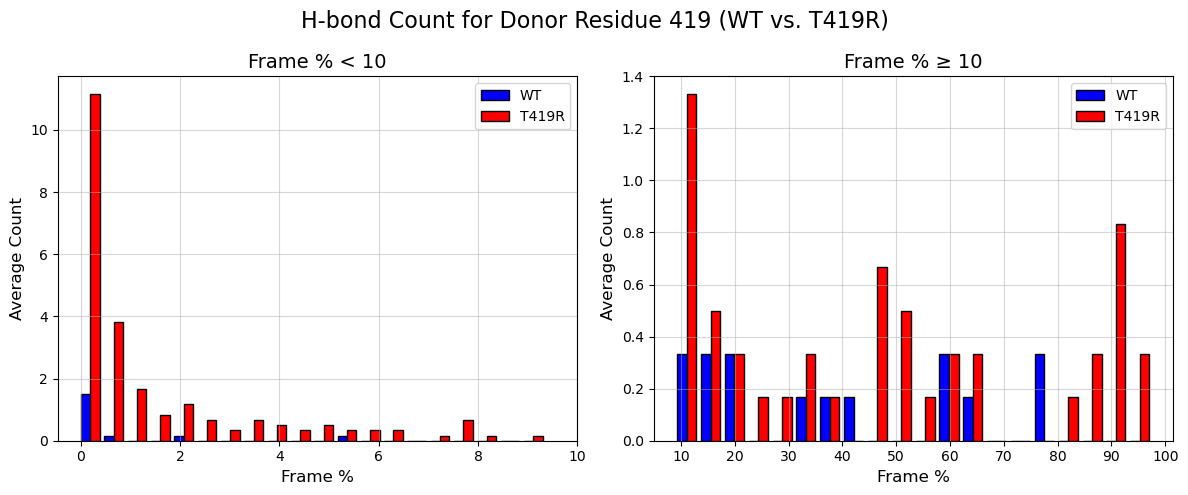

In [138]:

# Filter data
filtered_df_T419R = combined_df_T419R[combined_df_T419R['donor_res_num_adjusted'] == 419]
filtered_df_wt = combined_df_wt[combined_df_wt['donor_res_num_adjusted'] == 419]

# Split data into low (<10) and high (>=10) frame% values
wt_low = filtered_df_wt[filtered_df_wt['frame%'] < 10]['frame%']
wt_high = filtered_df_wt[filtered_df_wt['frame%'] >= 10]['frame%']
T419R_low = filtered_df_T419R[filtered_df_T419R['frame%'] < 10]['frame%']
T419R_high = filtered_df_T419R[filtered_df_T419R['frame%'] >= 10]['frame%']

# Create bins for low and high ranges
bins_low = np.histogram(np.hstack((wt_low, T419R_low)), bins=20)[1]
bins_high = np.histogram(np.hstack((wt_high, T419R_high)), bins=20)[1]

# Compute histogram counts
wt_counts_low, wt_bins_low = np.histogram(wt_low, bins=bins_low)
mut_counts_low, mut_bins_low = np.histogram(T419R_low, bins=bins_low)
wt_counts_high, wt_bins_high = np.histogram(wt_high, bins=bins_high)
mut_counts_high, mut_bins_high = np.histogram(T419R_high, bins=bins_high)

# Average counts by the number of replicates x number of methods
avg_wt_counts_low = wt_counts_low / (len(wt_dfs) * 2)
avg_mut_counts_low = mut_counts_low / (len(T419R_dfs) * 2)
avg_wt_counts_high = wt_counts_high / (len(wt_dfs) * 2)
avg_mut_counts_high = mut_counts_high / (len(T419R_dfs) * 2)

# Set up bar positions
bar_width_low = (bins_low[1] - bins_low[0]) * 0.4
bar_width_high = (bins_high[1] - bins_high[0]) * 0.4
wt_positions_low = bins_low[:-1]
mut_positions_low = bins_low[:-1] + bar_width_low
wt_positions_high = bins_high[:-1]
mut_positions_high = bins_high[:-1] + bar_width_high

# Create subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

# Plot low frame% (<10)
ax1.bar(wt_positions_low, avg_wt_counts_low, width=bar_width_low, color='blue', label='WT', edgecolor='black')
ax1.bar(mut_positions_low, avg_mut_counts_low, width=bar_width_low, color='red', label='T419R', edgecolor='black')
ax1.set_xlabel('Frame %', fontsize=12)
ax1.set_ylabel('Average Count', fontsize=12)
ax1.set_title('Frame % < 10', fontsize=14)
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.5)
ax1.set_xticks(np.arange(0, 11, 2)) 

# Plot high frame% (>=10)
ax2.bar(wt_positions_high, avg_wt_counts_high, width=bar_width_high, color='blue', label='WT', edgecolor='black')
ax2.bar(mut_positions_high, avg_mut_counts_high, width=bar_width_high, color='red', label='T419R', edgecolor='black')
ax2.set_xlabel('Frame %', fontsize=12)
ax2.set_ylabel('Average Count', fontsize=12)
ax2.set_title('Frame % ≥ 10', fontsize=14)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.5)
ax2.set_xticks(np.arange(10, 101, 10))  # Ticks every 10%, starting from 10

# Adjust layout and save
plt.suptitle('H-bond Count for Donor Residue 419 (WT vs. T419R)', fontsize=16)
plt.tight_layout()

In [60]:
filtered_df_T419R.shape

(183, 19)

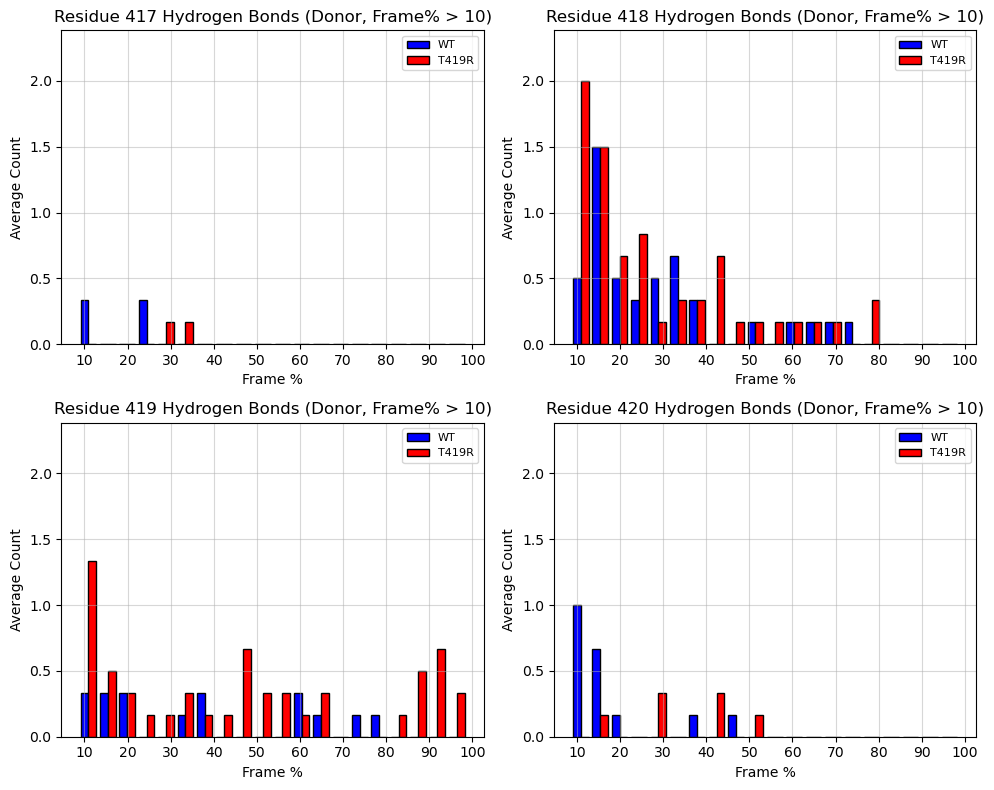

In [139]:

# Residues to plot
residues = [417, 418, 419, 420]

# Initialize a variable to track the maximum y-value
max_y_value = 0

# First pass: Calculate the maximum y-value across all residues
for residue in residues:
    # Filter data for the current residue and frame% > 10
    filtered_df_T419R = combined_df_T419R[(combined_df_T419R['donor_res_num_adjusted'] == residue) & (combined_df_T419R['frame%'] > 10)]
    filtered_df_wt = combined_df_wt[(combined_df_wt['donor_res_num_adjusted'] == residue) & (combined_df_wt['frame%'] > 10)]

    wt_counts, _ = np.histogram(filtered_df_wt['frame%'], bins=bins)
    mut_counts, _ = np.histogram(filtered_df_T419R['frame%'], bins=bins)

    # Average counts by the number of replicates x number of methods
    avg_wt_counts = wt_counts / (len(wt_dfs) * 2)
    avg_mut_counts = mut_counts / (len(T419R_dfs) * 2)

    # Update the maximum y-value
    max_y_value = max(max_y_value, max(avg_wt_counts), max(avg_mut_counts))

# Second pass: Plot the data
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()  # Flatten the 2D array of axes for easier indexing

for i, residue in enumerate(residues):
    # Filter data for the current residue and frame% > 10
    filtered_df_T419R = combined_df_T419R[(combined_df_T419R['donor_res_num_adjusted'] == residue) & (combined_df_T419R['frame%'] > 10)]
    filtered_df_wt = combined_df_wt[(combined_df_wt['donor_res_num_adjusted'] == residue) & (combined_df_wt['frame%'] > 10)]

    # Common bins
    bins = np.linspace(10, 100, 21)  # 21 edges for 20 bins
    wt_counts, _ = np.histogram(filtered_df_wt['frame%'], bins=bins)
    mut_counts, _ = np.histogram(filtered_df_T419R['frame%'], bins=bins)

    # Average counts by the number of replicates x number of methods
    avg_wt_counts = wt_counts / (len(wt_dfs) * 2)
    avg_mut_counts = mut_counts / (len(T419R_dfs) * 2)

    # Bar positions
    bar_width = (bins[1] - bins[0]) * 0.4
    wt_positions = bins[:-1]
    mut_positions = bins[:-1] + bar_width

    # Plot on the current subplot
    axes[i].bar(wt_positions, avg_wt_counts, width=bar_width, color='blue', label='WT', edgecolor='black')
    axes[i].bar(mut_positions, avg_mut_counts, width=bar_width, color='red', label='T419R', edgecolor='black')

    # Customize the subplot
    axes[i].set_xlabel('Frame %', fontsize=10)
    axes[i].set_ylabel('Average Count', fontsize=10)
    axes[i].set_title(f'Residue {residue} Hydrogen Bonds (Donor, Frame% > 10)', fontsize=12)
    axes[i].set_xticks(np.arange(10, 101, 10))  # Ticks every 10%, starting from 10
    axes[i].set_ylim(0, max_y_value * 1.1)  # Use the same y-axis range for all plots
    axes[i].grid(True, alpha=0.5)
    axes[i].legend(fontsize=8)

# Remove any unused subplot (if fewer than 6 residues)
for j in range(len(residues), len(axes)):
    fig.delaxes(axes[j])

# Adjust layout
plt.tight_layout()
plt.show()

Bonds where residue 419 is the donor and frame % > 10.

In [62]:
combined_df_T419R[(combined_df_T419R['donor_res_num_adjusted'] == 419) & (combined_df_T419R['frame%'] > 10)].shape

(40, 19)

In [140]:
combined_df_T419R[(combined_df_T419R['donor_res_num_adjusted'] == 419) & (combined_df_T419R['frame%'] > 10)].sort_values('frame%', ascending=False).head(10)

,donor,hydrogen,acceptor,count,frame%,donor_res_name,donor_res_num,donor_atom_name,donor_chain,acceptor_res_name,acceptor_res_num,acceptor_atom_name,acceptor_chain,donor_type,acceptor_type,donor_res_num_adjusted,acceptor_res_num_adjusted,donor_section,acceptor_section
156,14169,14170,19449,989,98.801199,ARG,284,N,B,DC,20,OP1,C,protein,DNA,419,20,DBD,backbone
52,4765,4767,20168,972,97.102897,ARG,284,NH2,A,DT,19,O2,D,protein,DNA,419,19,DBD,base
56,4765,4767,20168,944,94.305694,ARG,284,NH2,A,DT,19,O2,D,protein,DNA,419,19,DBD,base
151,14185,14187,19408,924,92.307692,ARG,284,NH1,B,DT,18,O2,C,protein,DNA,419,18,DBD,base
53,4765,4766,20184,920,91.908092,ARG,284,NH2,A,DG,20,O4',D,protein,DNA,419,20,DBD,backbone
58,4765,4767,20168,913,91.208791,ARG,284,NH2,A,DT,19,O2,D,protein,DNA,419,19,DBD,base
49,4762,4763,20168,910,90.909091,ARG,284,NH1,A,DT,19,O2,D,protein,DNA,419,19,DBD,base
162,14188,14190,19408,895,89.410589,ARG,284,NH2,B,DT,18,O2,C,protein,DNA,419,18,DBD,base
151,14185,14187,19408,878,87.712288,ARG,284,NH1,B,DT,18,O2,C,protein,DNA,419,18,DBD,base
61,4765,4767,20168,845,84.415584,ARG,284,NH2,A,DT,19,O2,D,protein,DNA,419,19,DBD,base


Acceptor residue sections. Are the hydrogen bonds happening with the DNA backbone or the bases?

In [143]:
def process_residue_data(residue, df, replicates):
    filtered_df = df[(df['donor_res_num_adjusted'] == residue) & (df['frame%'] > 10)]
    base = filtered_df[filtered_df['acceptor_section'] == 'base']
    backbone = filtered_df[filtered_df['acceptor_section'] == 'backbone']
    fixed_bins = np.linspace(10, 100, 21)  # 21 edges for 20 bins
    base_counts, _ = np.histogram(base['frame%'], bins=fixed_bins)
    backbone_counts, _ = np.histogram(backbone['frame%'], bins=fixed_bins)
    norm_base = base_counts / (replicates * 2)  # Multiply by 2 for two methods
    norm_backbone = backbone_counts / (replicates  * 2)  # Multiply by 2 for two methods
    return norm_base, norm_backbone, fixed_bins

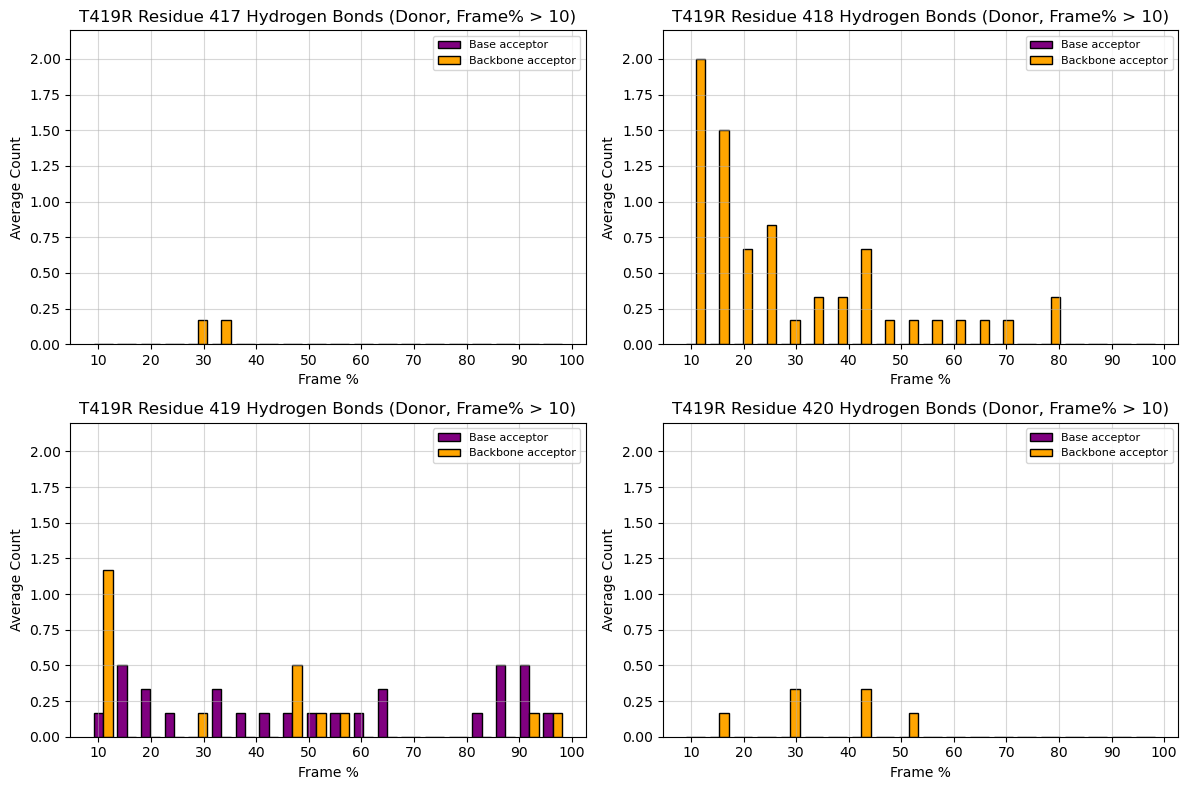

In [147]:
residues = [417, 418, 419, 420]
max_y_value = 0
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
axes = axes.flatten()

for i, residue in enumerate(residues):
    norm_base, norm_backbone, bins = process_residue_data(residue, combined_df_T419R, len(T419R_dfs))
    max_y_value = max(max_y_value, max(norm_base), max(norm_backbone))

    bar_width = (bins[1] - bins[0]) * 0.4
    axes[i].bar(bins[:-1], norm_base, width=bar_width, color='purple', label='Base acceptor', edgecolor='black')
    axes[i].bar(bins[:-1] + bar_width, norm_backbone, width=bar_width, color='orange', label='Backbone acceptor', edgecolor='black')

    axes[i].set_xlabel('Frame %', fontsize=10)
    axes[i].set_ylabel('Average Count', fontsize=10)
    axes[i].set_title(f'T419R Residue {residue} Hydrogen Bonds (Donor, Frame% > 10)', fontsize=12)
    axes[i].set_xticks(np.arange(10, 101, 10))
    axes[i].tick_params(axis='y', labelleft=True)
    axes[i].set_ylim(0, max_y_value * 1.1)
    axes[i].grid(True, alpha=0.5)
    axes[i].legend(fontsize=8)

for j in range(len(residues), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

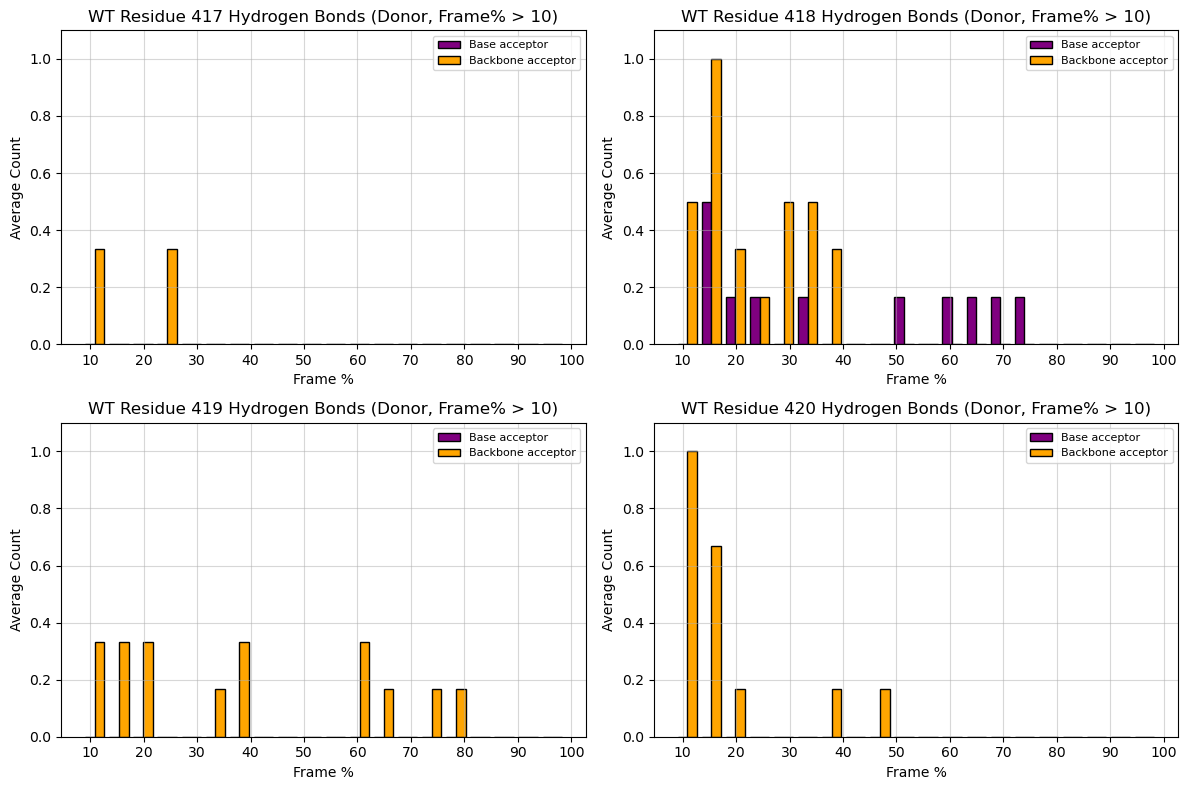

In [149]:
residues = [417, 418, 419, 420]
max_y_value = 0
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
axes = axes.flatten()

for i, residue in enumerate(residues):
    norm_base, norm_backbone, bins = process_residue_data(residue, combined_df_wt, len(wt_dfs))
    max_y_value = max(max_y_value, max(norm_base), max(norm_backbone))

    bar_width = (bins[1] - bins[0]) * 0.4
    axes[i].bar(bins[:-1], norm_base, width=bar_width, color='purple', label='Base acceptor', edgecolor='black')
    axes[i].bar(bins[:-1] + bar_width, norm_backbone, width=bar_width, color='orange', label='Backbone acceptor', edgecolor='black')

    axes[i].set_xlabel('Frame %', fontsize=10)
    axes[i].set_ylabel('Average Count', fontsize=10)
    axes[i].set_title(f'WT Residue {residue} Hydrogen Bonds (Donor, Frame% > 10)', fontsize=12)
    axes[i].set_xticks(np.arange(10, 101, 10))
    axes[i].tick_params(axis='y', labelleft=True)
    axes[i].set_ylim(0, max_y_value * 1.1)
    axes[i].grid(True, alpha=0.5)
    axes[i].legend(fontsize=8)

for j in range(len(residues), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**DNA residues binding to residue 419**

Note that these bonds are NOT filtered fo frame % > 10.

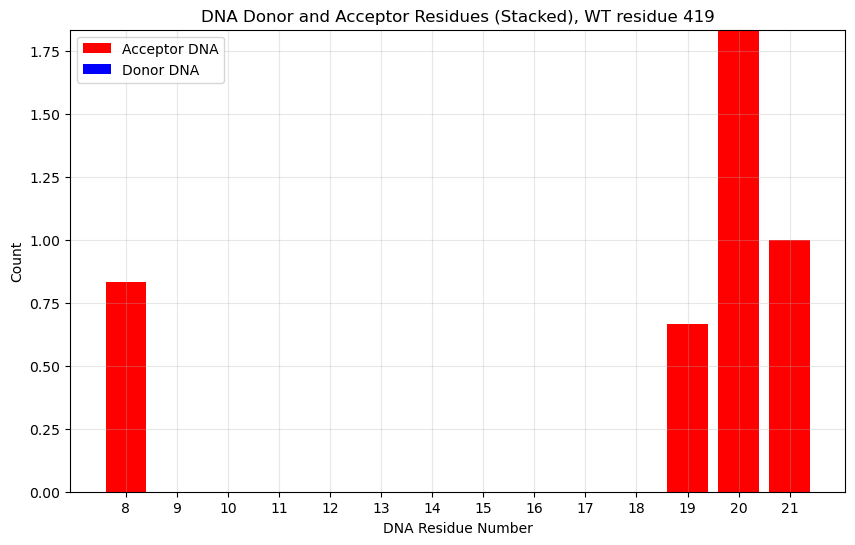

In [150]:
donor_wt = combined_df_wt[combined_df_wt['donor_res_num_adjusted'] == 419]
acceptor_wt = combined_df_wt[combined_df_wt['acceptor_res_num_adjusted'] == 419]

donor_counts = donor_wt['acceptor_res_num_adjusted'].value_counts().sort_index()
acceptor_counts = acceptor_wt['donor_res_num_adjusted'].value_counts().sort_index()

plt.figure(figsize=(10, 6))

# Get all unique residue numbers
all_res_nums = sorted(set(donor_counts.index).union(acceptor_counts.index))

# Align the counts, filling with 0 where no data exists
donor_values = [donor_counts.get(num, 0) / (len(wt_dfs) * 2) for num in all_res_nums]
acceptor_values = [acceptor_counts.get(num, 0) / (len(wt_dfs) * 2) for num in all_res_nums]

# Create stacked bar plot
plt.bar(all_res_nums, donor_values, color='red', label='Acceptor DNA')
plt.bar(all_res_nums, acceptor_values, bottom=donor_values, color='blue', label='Donor DNA')

# Set x-ticks for every unit
min_residue = min(all_res_nums)
max_residue = max(all_res_nums)
plt.xticks(range(int(min_residue), int(max_residue) + 1, 1))

plt.xlabel('DNA Residue Number')
plt.ylabel('Count')
plt.title('DNA Donor and Acceptor Residues (Stacked), WT residue 419')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

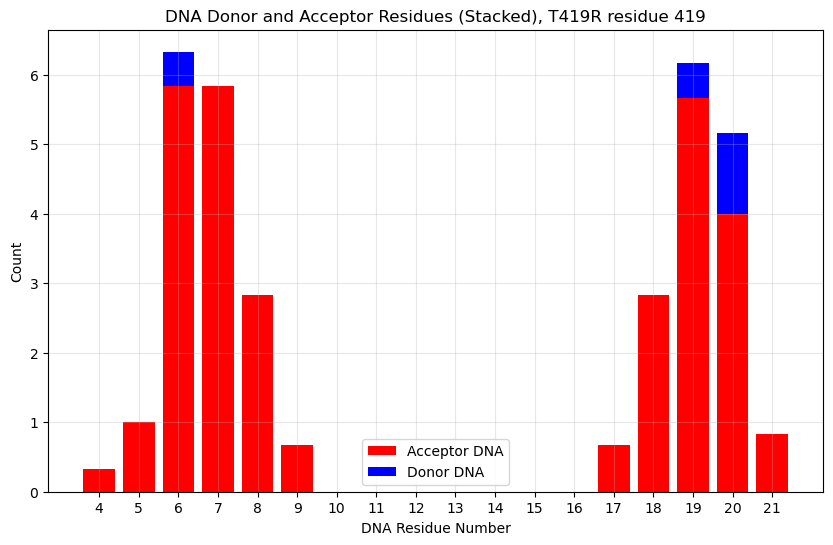

In [151]:
donor_T419R = combined_df_T419R[combined_df_T419R['donor_res_num_adjusted'] == 419]
acceptor_T419R = combined_df_T419R[combined_df_T419R['acceptor_res_num_adjusted'] == 419]

donor_counts = donor_T419R['acceptor_res_num_adjusted'].value_counts().sort_index()
acceptor_counts = acceptor_T419R['donor_res_num_adjusted'].value_counts().sort_index()

plt.figure(figsize=(10, 6))

# Get all unique residue numbers
all_res_nums = sorted(set(donor_counts.index).union(acceptor_counts.index))

# Align the counts, filling with 0 where no data exists
donor_values = [donor_counts.get(num, 0) / (len(T419R_dfs) * 2) for num in all_res_nums]
acceptor_values = [acceptor_counts.get(num, 0) / (len(T419R_dfs) * 2) for num in all_res_nums]

# Create stacked bar plot
plt.bar(all_res_nums, donor_values, color='red', label='Acceptor DNA')
plt.bar(all_res_nums, acceptor_values, bottom=donor_values, color='blue', label='Donor DNA')

# Set x-ticks for every unit
min_residue = min(all_res_nums)
max_residue = max(all_res_nums)
plt.xticks(range(int(min_residue), int(max_residue) + 1, 1))

plt.xlabel('DNA Residue Number')
plt.ylabel('Count')
plt.title('DNA Donor and Acceptor Residues (Stacked), T419R residue 419')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


In [152]:
# Define the DNA strands
strand1 = "CGACAGTTTCCCGGAAATGCAGC"  # Chain C, 23 nucleotides
strand2 = "GCTGCATTTCCGGGAAACTGTCG"  # Chain D, 23 nucleotides

# Create a mapping of residue numbers to nucleotide pairs
residue_to_nucleotides = {i+1: (strand1[i], strand2[i]) for i in range(23)}

# Consensus residues
consensus_residues = [8, 9, 10, 11, 13, 14, 15, 16]

In [153]:
def plot_interactions(ax, df_donor, df_acceptor, section, title, replicates):
    # Filter for section
    donor = df_donor[df_donor['acceptor_section'] == section]
    acceptor = df_acceptor[df_acceptor['donor_section'] == section]

    # Print donor table
    donor_table = donor[['acceptor_res_num_adjusted', 'acceptor_res_name', 'acceptor_chain']].drop_duplicates().sort_values('acceptor_chain')
    print(f"\nDonor Table for {section} interactions:")
    print(donor_table.to_string(index=False))
    
    # Print acceptor table
    acceptor_table = acceptor[['donor_res_num_adjusted', 'donor_res_name', 'donor_chain']].drop_duplicates().sort_values('donor_chain')
    print(f"\nAcceptor Table for {section} interactions:")
    print(acceptor_table.to_string(index=False))
    
    # Count occurrences
    donor_counts = donor['acceptor_res_num_adjusted'].value_counts().sort_index()
    acceptor_counts = acceptor['donor_res_num_adjusted'].value_counts().sort_index()
    
    # Define all residue numbers (1 to 23, based on DNA strands)
    all_res_nums = list(range(1, 24))  # Residues 1 to 23 inclusive
    
    # Average counts, using 0 for residues with no counts
    donor_values = [donor_counts.get(num, 0) / (replicates * 2) for num in all_res_nums]
    acceptor_values = [acceptor_counts.get(num, 0) / (replicates * 2) for num in all_res_nums]
    
    # Create stacked bar plot
    ax.bar(all_res_nums, donor_values, color='red', label='Acceptor DNA')
    ax.bar(all_res_nums, acceptor_values, bottom=donor_values, color='blue', label='Donor DNA')
    
    # Set x-ticks to include all residues (1 to 23)
    ax.set_xticks(all_res_nums)
    ax.tick_params(axis='x', rotation=45)
    
    # Customize plot
    ax.set_xlabel('DNA Residue Number')
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend()

In [154]:
def plot_dnaseq_bb_base(df_donor, df_acceptor, replicates, section1, title1, section2, title2):
    # Create figure with two subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 6), sharey=True)
    ax1.set_ylabel('Average Count', fontsize=12)

    # Plot backbone and base interactions (assuming plot_interactions is defined)
    plot_interactions(ax1, df_donor, df_acceptor, section1, title1, replicates)
    plot_interactions(ax2, df_donor, df_acceptor, section2, title2, replicates)

    # Calculate the maximum value from both plots and add a margin
    y_max_ax1 = max(ax1.get_ylim())
    y_max_ax2 = max(ax2.get_ylim())
    y_max = max(y_max_ax1, y_max_ax2) * 1.1  # Add a 10% margin

    # Customize x-axis labels to include residue number, Chain C nucleotide, and Chain D nucleotide
    for ax in [ax1, ax2]:
        ticks = ax.get_xticks()
        # Filter ticks to ensure they are within the residue range (1-23)
        valid_ticks = [int(t) for t in ticks if t.is_integer() and 1 <= t <= 23]
        labels = [f"{res}\n{residue_to_nucleotides.get(res, ('N/A', 'N/A'))[0]}\n{residue_to_nucleotides.get(res, ('N/A', 'N/A'))[1]}" 
                for res in valid_ticks]
        ax.set_xticks(valid_ticks)
        ax.set_xticklabels(labels, fontsize=10, rotation=0, ha='right', va='top')

        # Color consensus sequence residues green
        for i, label in enumerate(ax.get_xticklabels()):
            if valid_ticks[i] in consensus_residues:
                label.set_color('green')
                label.set_weight('bold')
        
        ax.set_xlabel('Residue Number\nChain C\nChain D', fontsize=12)
        ax.set_xlabel('Residue Number\nChain C\nChain D', fontsize=12)

    # Adjust layout to prevent label clipping
    plt.tight_layout()
    plt.show()


Donor Table for backbone interactions:
 acceptor_res_num_adjusted acceptor_res_name acceptor_chain
                         6                DG              C
                         7                DT              C
                         5                DA              C
                        20                DC              C
                        19                DG              C
                        18                DT              C
                        20                DG              D
                        21                DT              D
                         8                DT              D
                        19                DT              D
                         7                DT              D
                         9                DT              D

Acceptor Table for backbone interactions:
Empty DataFrame
Columns: [donor_res_num_adjusted, donor_res_name, donor_chain]
Index: []

Donor Table for base interactions:
 acceptor_re

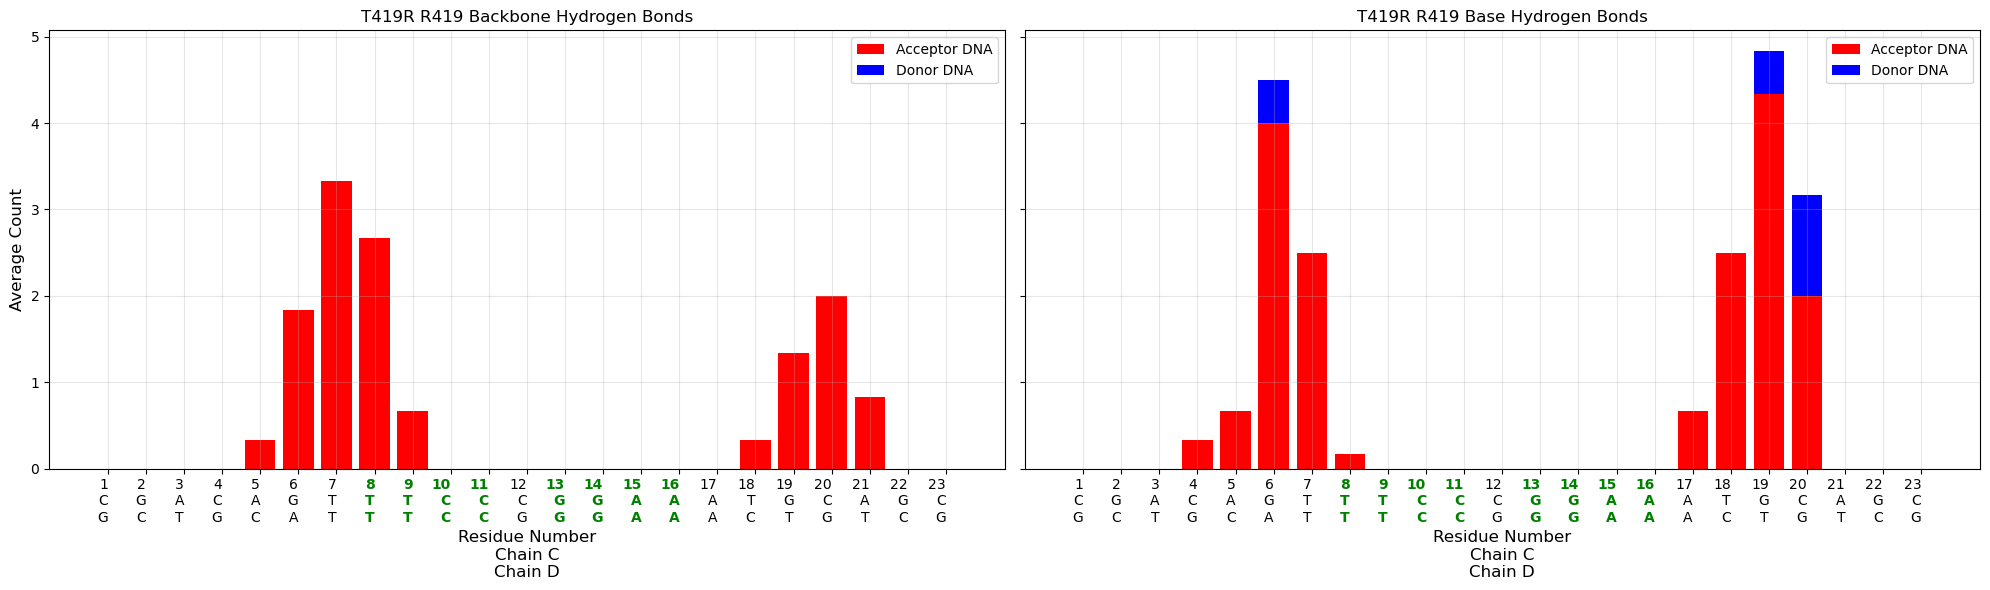

In [155]:
mut = 'T419R'
focus_resid = 419
focus_resn = 'R'
reps = len(T419R_dfs)
title_common = f'{mut} {focus_resn}{focus_resid}' 

# Filter data for donor and acceptor at residue 419
donor_T419R = combined_df_T419R[combined_df_T419R['donor_res_num_adjusted'] == focus_resid]
acceptor_T419R = combined_df_T419R[combined_df_T419R['acceptor_res_num_adjusted'] == focus_resid]

plot_dnaseq_bb_base(donor_T419R, acceptor_T419R, reps, 'backbone', f'{title_common} Backbone Hydrogen Bonds',
                    'base', f'{title_common} Base Hydrogen Bonds')


Donor Table for backbone interactions:
 acceptor_res_num_adjusted acceptor_res_name acceptor_chain
                         7                DT              C
                         8                DT              C
                        20                DC              C
                        18                DT              C
                        19                DG              C
                        21                DA              C
                        19                DT              D
                        20                DG              D
                         8                DT              D
                         9                DT              D
                        21                DT              D
                        22                DC              D

Acceptor Table for backbone interactions:
Empty DataFrame
Columns: [donor_res_num_adjusted, donor_res_name, donor_chain]
Index: []

Donor Table for base interactions:
 acceptor_re

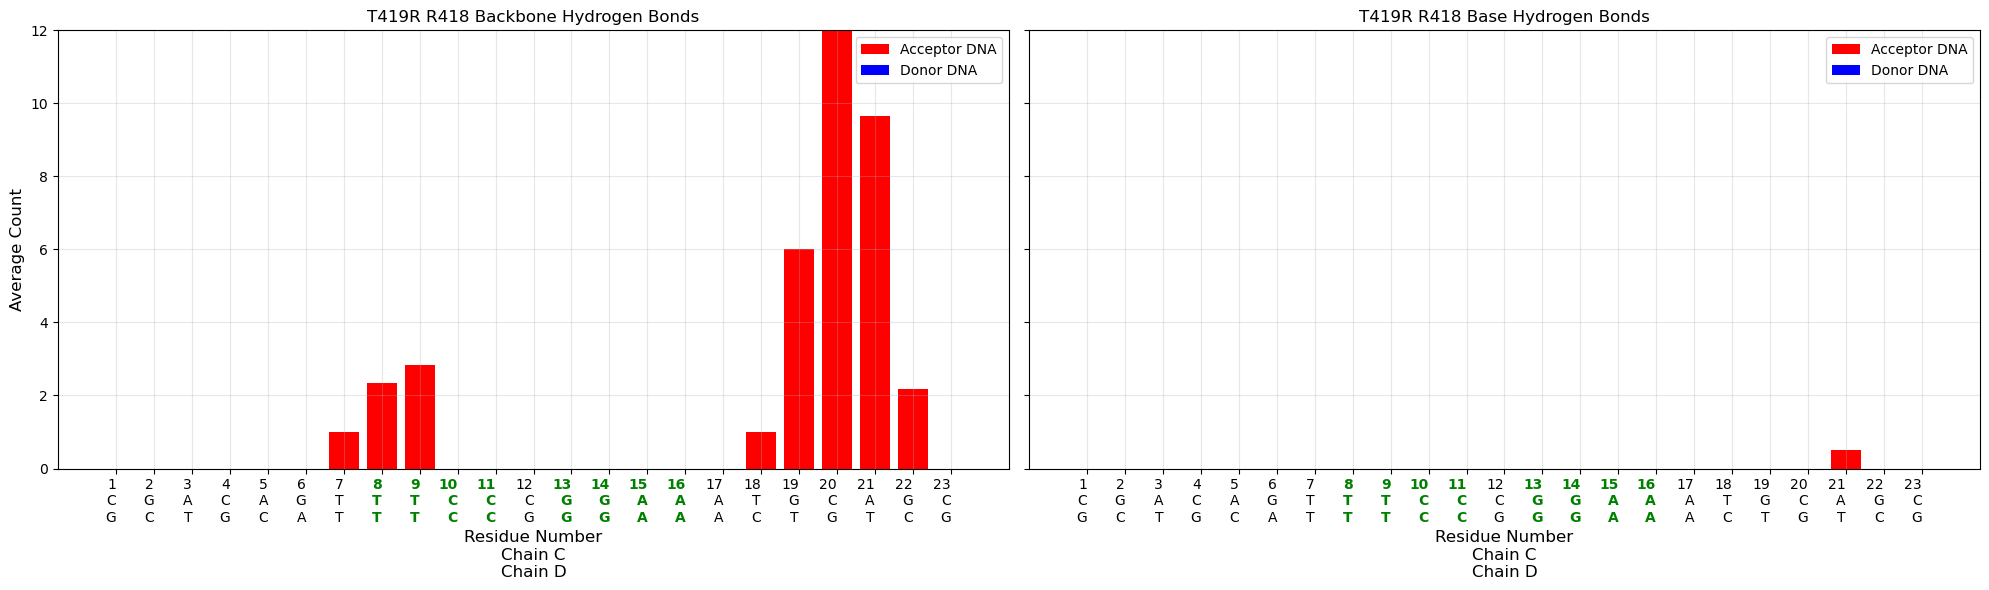

In [156]:
mut = 'T419R'
focus_resid = 418
focus_resn = 'R'
reps = len(T419R_dfs)
title_common = f'{mut} {focus_resn}{focus_resid}' 

# Filter data for donor and acceptor at residue 419
donor_T419R = combined_df_T419R[combined_df_T419R['donor_res_num_adjusted'] == focus_resid]
acceptor_T419R = combined_df_T419R[combined_df_T419R['acceptor_res_num_adjusted'] == focus_resid]

plot_dnaseq_bb_base(donor_T419R, acceptor_T419R, reps, 'backbone', f'{title_common} Backbone Hydrogen Bonds',
                    'base', f'{title_common} Base Hydrogen Bonds')


Donor Table for backbone interactions:
 acceptor_res_num_adjusted acceptor_res_name acceptor_chain
                        21                DA              C
                        20                DG              D
                         8                DT              D
                        19                DT              D

Acceptor Table for backbone interactions:
Empty DataFrame
Columns: [donor_res_num_adjusted, donor_res_name, donor_chain]
Index: []

Donor Table for base interactions:
Empty DataFrame
Columns: [acceptor_res_num_adjusted, acceptor_res_name, acceptor_chain]
Index: []

Acceptor Table for base interactions:
Empty DataFrame
Columns: [donor_res_num_adjusted, donor_res_name, donor_chain]
Index: []


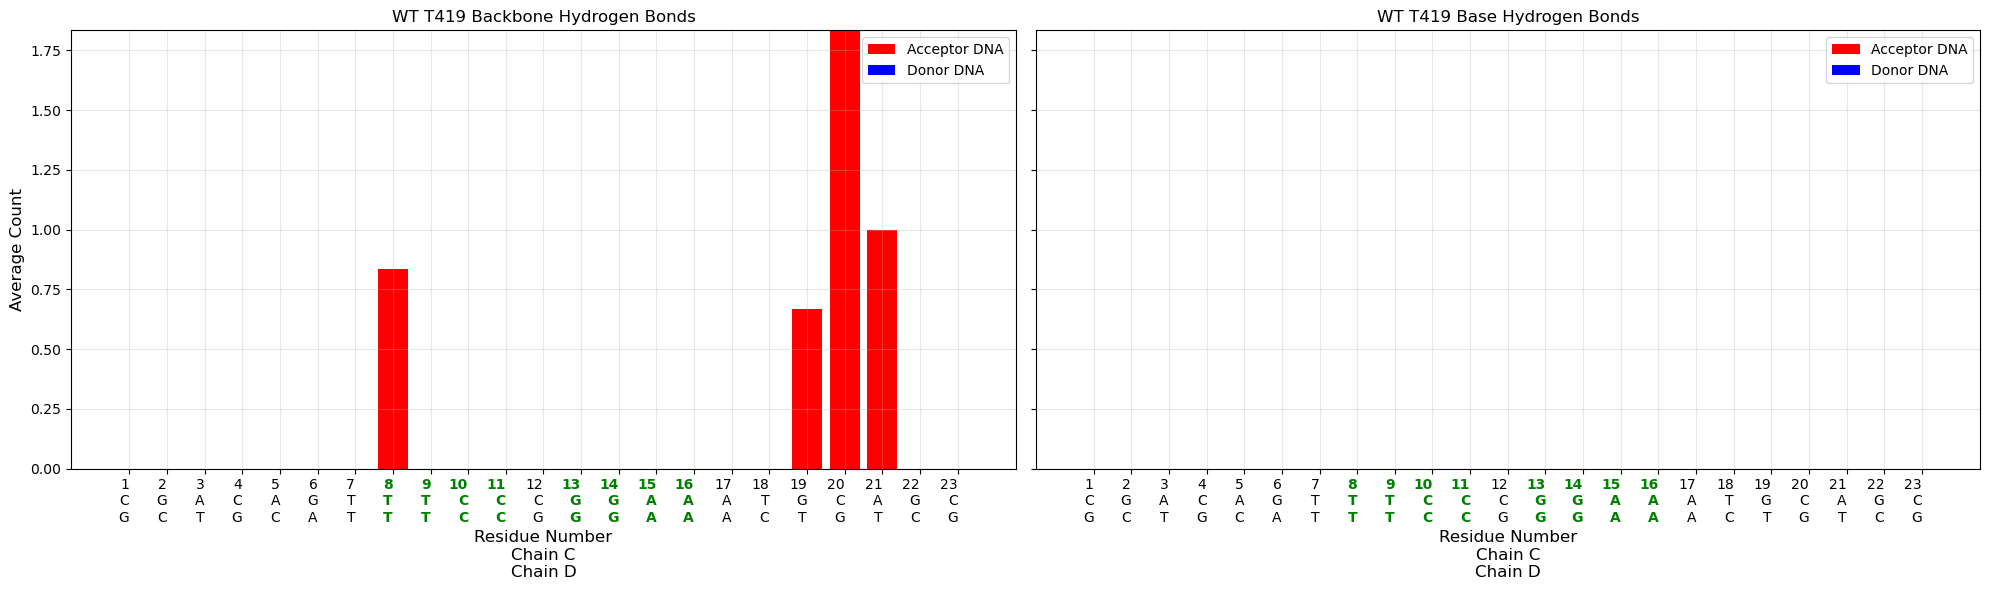

In [157]:
mut = 'WT'
focus_resid = 419
focus_resn = 'T'
reps = len(wt_dfs)
title_common = f'{mut} {focus_resn}{focus_resid}' 

# Filter data for donor and acceptor at residue 419
donor_wt = combined_df_wt[combined_df_wt['donor_res_num_adjusted'] == focus_resid]
acceptor_wt= combined_df_wt[combined_df_wt['acceptor_res_num_adjusted'] == focus_resid]

plot_dnaseq_bb_base(donor_wt, acceptor_wt, reps, 'backbone', f'{title_common} Backbone Hydrogen Bonds',
                    'base', f'{title_common} Base Hydrogen Bonds')


Donor Table for backbone interactions:
 acceptor_res_num_adjusted acceptor_res_name acceptor_chain
                        19                DG              C
                        20                DC              C
                        18                DT              C
                        21                DA              C
                        20                DG              D
                        19                DT              D
                         8                DT              D
                         7                DT              D
                         6                DA              D
                        21                DT              D

Acceptor Table for backbone interactions:
Empty DataFrame
Columns: [donor_res_num_adjusted, donor_res_name, donor_chain]
Index: []

Donor Table for base interactions:
 acceptor_res_num_adjusted acceptor_res_name acceptor_chain
                        19                DG              C
            

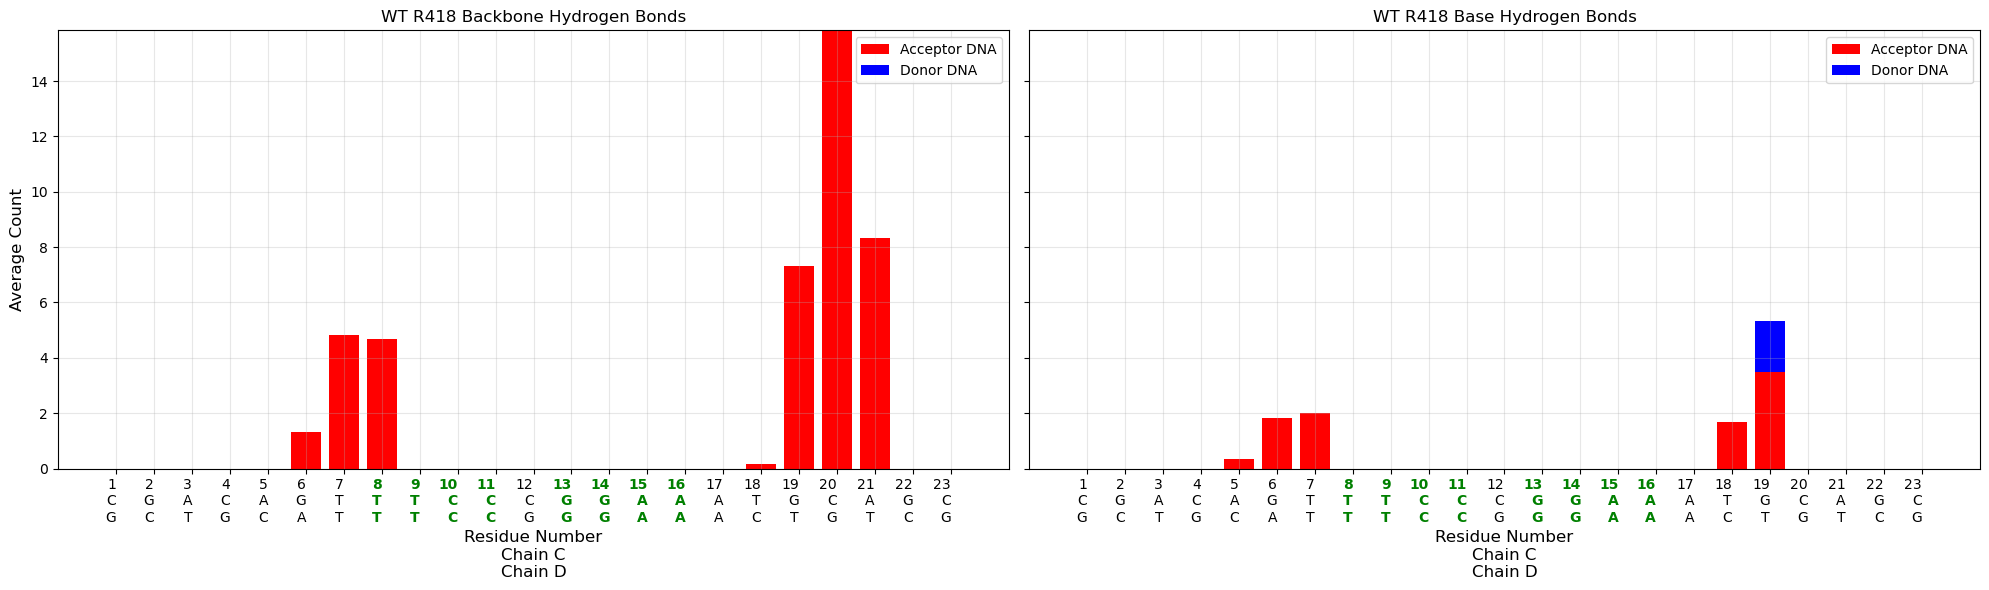

In [159]:
mut = 'WT'
focus_resid = 418
focus_resn = 'R'
reps = len(wt_dfs)
title_common = f'{mut} {focus_resn}{focus_resid}' 

# Filter data for donor and acceptor at residue 419
donor_wt = combined_df_wt[combined_df_wt['donor_res_num_adjusted'] == focus_resid]
acceptor_wt= combined_df_wt[combined_df_wt['acceptor_res_num_adjusted'] == focus_resid]

plot_dnaseq_bb_base(donor_wt, acceptor_wt, reps, 'backbone', f'{title_common} Backbone Hydrogen Bonds',
                    'base', f'{title_common} Base Hydrogen Bonds')

## Other mutations: R274W, R321S, E411A, N574I

Extract upregulated gene lists.

In [ ]:
up_cols = df_up.columns
up_cols 

Index(['WT', 'R274W', 'R321S', 'E411A', 'T419R', 'N574I'], dtype='object')

In [ ]:
for col in up_cols :
    df_up[col].dropna().to_csv(f'up_{col}.txt', index=False)

Find motifs with the default promoter region (-300, +50).

In [ ]:
for col in ['R274W', 'R321S', 'E411A', 'N574I']:
    cmd = f"findMotifs.pl up_{col}.txt human up_{col}/ -p 14 &> log/log_findMotifs_{col}.log"
    !{cmd}

^C


In [ ]:
for col in ['R274W', 'R321S', 'E411A', 'N574I']:
    cmd = f"findMotifs.pl up_{col}.txt human up_{col}_200_50/ -p 14 -start -200 -end 50 &> log/log_findMotifs_{col}_200_50.log"
    !{cmd}

### Known motifs

In [ ]:
motif_dfs = {}

for col in up_cols:
    key_motifs = f"{col}_motifs"
    key_motifs_200_50 = f"{col}_motifs_200_50"

    print(key_motifs)
    motif_dfs[key_motifs] = pd.read_csv(f"up_{col}/knownResults.txt", sep="\t")
    print(motif_dfs[key_motifs].shape)
    
    print(key_motifs_200_50)
    motif_dfs[key_motifs_200_50] = pd.read_csv(f"up_{col}_200_50/knownResults.txt", sep="\t")
    print(motif_dfs[key_motifs_200_50].shape)


WT_motifs
(472, 9)
WT_motifs_200_50
(472, 9)
R274W_motifs
(472, 9)
R274W_motifs_200_50
(472, 9)
R321S_motifs
(472, 9)
R321S_motifs_200_50
(472, 9)
E411A_motifs
(472, 9)
E411A_motifs_200_50
(472, 9)
T419R_motifs
(472, 9)
T419R_motifs_200_50
(472, 9)
N574I_motifs
(472, 9)
N574I_motifs_200_50
(472, 9)


In [ ]:
motif_dfs.keys()

dict_keys(['WT_motifs', 'WT_motifs_200_50', 'R274W_motifs', 'R274W_motifs_200_50', 'R321S_motifs', 'R321S_motifs_200_50', 'E411A_motifs', 'E411A_motifs_200_50', 'T419R_motifs', 'T419R_motifs_200_50', 'N574I_motifs', 'N574I_motifs_200_50'])

In [ ]:
motif_keys = list(motif_dfs.keys())  # Convert dict_keys to a list
comparison = motif_dfs[motif_keys[0]].drop_duplicates(subset="Motif Name").copy()
comparison.name = motif_keys[0].replace('_motifs', '')

# Merge with the rest
for key in motif_keys[1:]:
    right_df = motif_dfs[key].drop_duplicates(subset="Motif Name")
    right_df.name = key.replace('_motifs', '')
    comparison = pd.merge(
        comparison,
        right_df,
        on="Motif Name",
        how="outer",
        suffixes=(f"_{comparison.name}", f"_{right_df.name}")
    )
    comparison.name = right_df.name  # Update name for next iteration

In [ ]:
comparison.columns

Index(['Motif Name', 'Consensus_WT', 'P-value_WT', 'Log P-value_WT',
       'q-value (Benjamini)_WT', '# of Target Sequences with Motif(of 46)_WT',
       '% of Target Sequences with Motif_WT',
       '# of Background Sequences with Motif(of 43551)',
       '% of Background Sequences with Motif_WT', 'Consensus_WT_200_50',
       'P-value_WT_200_50', 'Log P-value_WT_200_50',
       'q-value (Benjamini)_WT_200_50',
       '# of Target Sequences with Motif(of 46)_WT_200_50',
       '% of Target Sequences with Motif_WT_200_50',
       '# of Background Sequences with Motif(of 42368)',
       '% of Background Sequences with Motif_WT_200_50', 'Consensus_R274W',
       'P-value_R274W', 'Log P-value_R274W', 'q-value (Benjamini)_R274W',
       '# of Target Sequences with Motif(of 121)_R274W',
       '% of Target Sequences with Motif_R274W',
       '# of Background Sequences with Motif(of 45218)',
       '% of Background Sequences with Motif_R274W', 'Consensus_R274W_200_50',
       'P-value_R274W

In [ ]:
# Assuming 'comparison' is the merged DataFrame from your previous step
# Select columns: 'Motif Name' and all 'P-value_{mutation}' columns
pvalue_cols = [col for col in comparison.columns if col.startswith('P-value_')]

# Create a DataFrame with only the relevant columns
df_pvalues = comparison[['Motif Name'] + pvalue_cols].copy()

In [ ]:
df_pvalues.head()

,Motif Name,P-value_WT,P-value_WT_200_50,P-value_R274W,P-value_R274W_200_50,P-value_R321S,P-value_R321S_200_50,P-value_E411A,P-value_E411A_200_50,P-value_T419R,P-value_T419R_200_50,P-value_N574I,P-value_N574I_200_50
0,AMYB(HTH)/Testes-AMYB-ChIP-Seq(GSE44588)/Homer,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0
1,AP-1(bZIP)/ThioMac-PU.1-ChIP-Seq(GSE21512)/Homer,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.01,1.0,1.0,0.1,0.1
2,AP-2alpha(AP2)/Hela-AP2alpha-ChIP-Seq(GSE31477...,1.0,1.0,0.1,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0
3,AP-2gamma(AP2)/MCF7-TFAP2C-ChIP-Seq(GSE21234)/...,1.0,1.0,0.1,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0
4,AR-halfsite(NR)/LNCaP-AR-ChIP-Seq(GSE27824)/Homer,1.0,0.1,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.0


In [ ]:
# Filter for rows where any P-value column is less than or equal to 0.05
df_pvalues_filtered = df_pvalues[df_pvalues[pvalue_cols].astype(float).le(0.05).any(axis=1)]
df_pvalues_filtered.head()

,Motif Name,P-value_WT,P-value_WT_200_50,P-value_R274W,P-value_R274W_200_50,P-value_R321S,P-value_R321S_200_50,P-value_E411A,P-value_E411A_200_50,P-value_T419R,P-value_T419R_200_50,P-value_N574I,P-value_N574I_200_50
1,AP-1(bZIP)/ThioMac-PU.1-ChIP-Seq(GSE21512)/Homer,0.1,0.1,0.10,0.10,0.10,0.10,0.10,0.01,1.0,1.00,0.1,0.10
18,BATF(bZIP)/Th17-BATF-ChIP-Seq(GSE39756)/Homer,0.1,0.1,1.00,1.00,0.10,0.10,0.01,0.01,1.0,1.00,0.1,0.10
31,"Brn2(POU,Homeobox)/NPC-Brn2-ChIP-Seq(GSE35496)...",1.0,1.0,1.00,1.00,1.00,1.00,1.00,1.00,0.1,0.01,1.0,1.00
53,DMRT1(DM)/Testis-DMRT1-ChIP-Seq(GSE64892)/Homer,0.1,0.1,1.00,1.00,1.00,0.10,0.01,0.01,1.0,0.10,0.1,0.01
55,DUX(Homeobox)/C2C12-Dux-ChIP-Seq(GSE87279)/Homer,1.0,1.0,0.01,0.01,0.01,0.01,1.00,1.00,0.1,1.00,0.1,1.00


In [ ]:
# Pivot the DataFrame to have 'Motif Name' as index and mutations as columns
# Extract mutation names from column names (e.g., 'P-value_WT' -> 'WT')
df_pvalues_filtered.columns = ['Motif Name'] + [col.replace('P-value_', '') for col in df_pvalues.columns if col.startswith('P-value_')]
df_pivot = df_pvalues_filtered.set_index('Motif Name')
df_pivot.head()

,WT,WT_200_50,R274W,R274W_200_50,R321S,R321S_200_50,E411A,E411A_200_50,T419R,T419R_200_50,N574I,N574I_200_50
Motif Name,,,,,,,,,,,,
AP-1(bZIP)/ThioMac-PU.1-ChIP-Seq(GSE21512)/Homer,0.1,0.1,0.10,0.10,0.10,0.10,0.10,0.01,1.0,1.00,0.1,0.10
BATF(bZIP)/Th17-BATF-ChIP-Seq(GSE39756)/Homer,0.1,0.1,1.00,1.00,0.10,0.10,0.01,0.01,1.0,1.00,0.1,0.10
"Brn2(POU,Homeobox)/NPC-Brn2-ChIP-Seq(GSE35496)/Homer",1.0,1.0,1.00,1.00,1.00,1.00,1.00,1.00,0.1,0.01,1.0,1.00
DMRT1(DM)/Testis-DMRT1-ChIP-Seq(GSE64892)/Homer,0.1,0.1,1.00,1.00,1.00,0.10,0.01,0.01,1.0,0.10,0.1,0.01
DUX(Homeobox)/C2C12-Dux-ChIP-Seq(GSE87279)/Homer,1.0,1.0,0.01,0.01,0.01,0.01,1.00,1.00,0.1,1.00,0.1,1.00


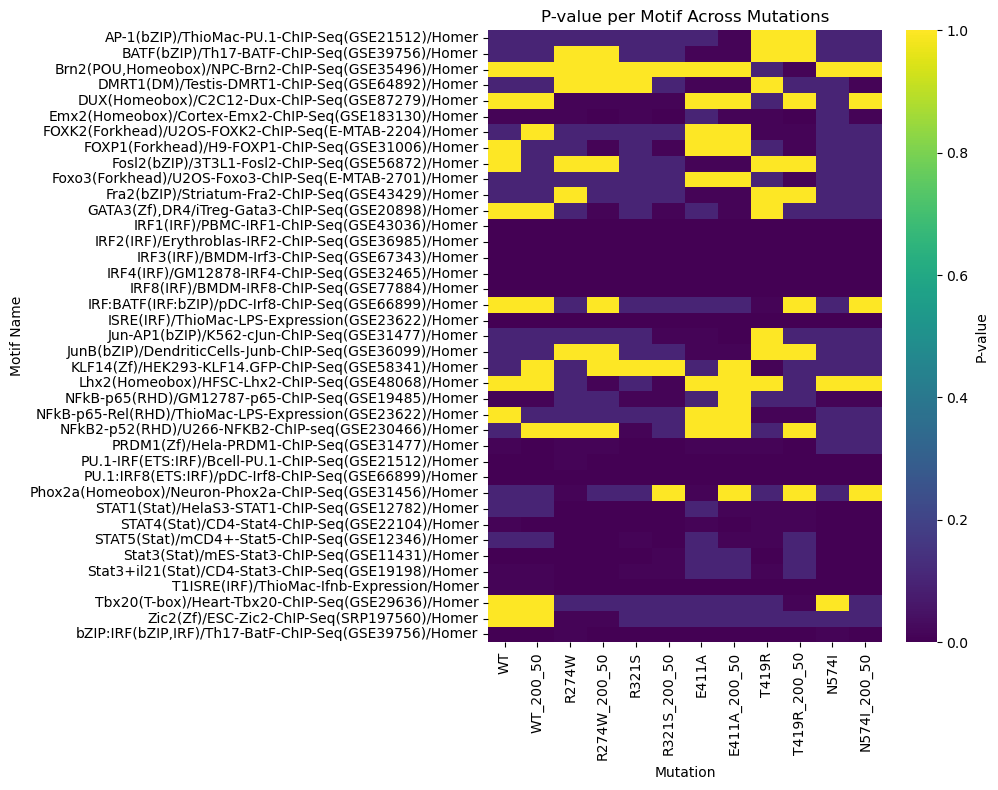

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(df_pivot, cmap='viridis', cbar_kws={'label': 'P-value'})
plt.title('P-value per Motif Across Mutations')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

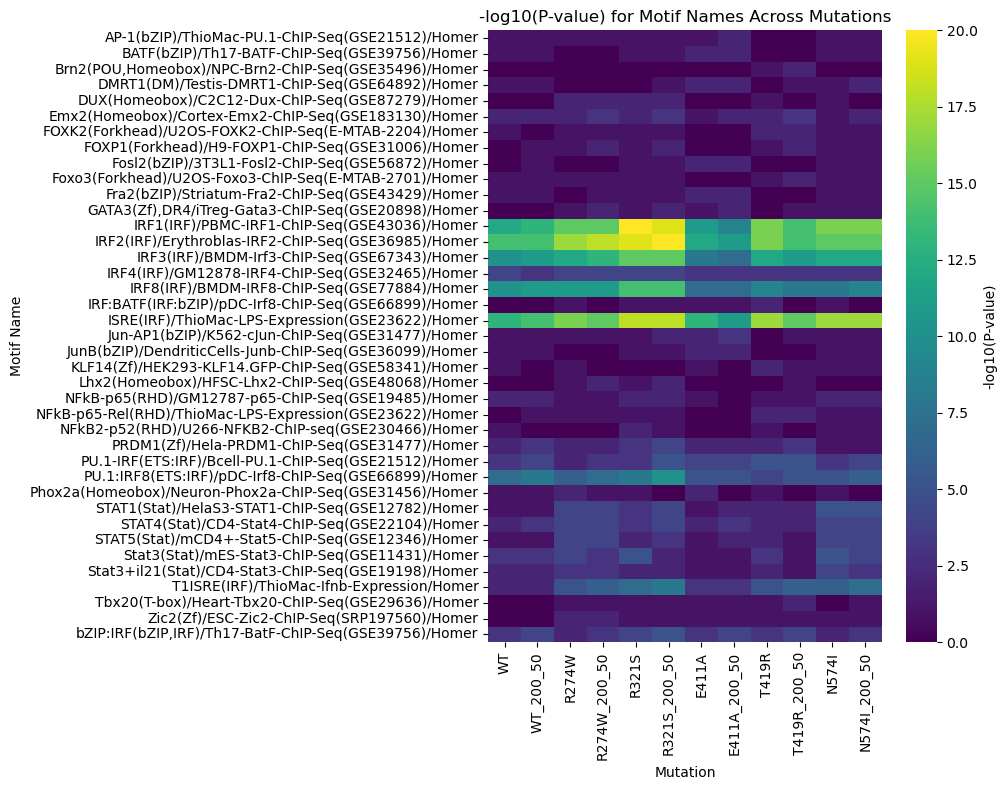

In [ ]:
df_pivot_log10 = -np.log10(df_pivot)

plt.figure(figsize=(10, 8))
sns.heatmap(df_pivot_log10, cmap='viridis', cbar_kws={'label': '-log10(P-value)'})
plt.title('-log10(P-value) for Motif Names Across Mutations')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

In [ ]:
df_pivot.columns

Index(['WT', 'WT_200_50', 'R274W', 'R274W_200_50', 'R321S', 'R321S_200_50',
       'E411A', 'E411A_200_50', 'T419R', 'T419R_200_50', 'N574I',
       'N574I_200_50'],
      dtype='object')

In [ ]:
df_pivot_bool = df_pivot.copy()
df_pivot_bool[df_pivot.columns] = np.where(df_pivot[df_pivot.columns] < 0.05, 1, 0)
df_pivot_bool.head()

,WT,WT_200_50,R274W,R274W_200_50,R321S,R321S_200_50,E411A,E411A_200_50,T419R,T419R_200_50,N574I,N574I_200_50
Motif Name,,,,,,,,,,,,
AP-1(bZIP)/ThioMac-PU.1-ChIP-Seq(GSE21512)/Homer,0,0,0,0,0,0,0,1,0,0,0,0
BATF(bZIP)/Th17-BATF-ChIP-Seq(GSE39756)/Homer,0,0,0,0,0,0,1,1,0,0,0,0
"Brn2(POU,Homeobox)/NPC-Brn2-ChIP-Seq(GSE35496)/Homer",0,0,0,0,0,0,0,0,0,1,0,0
DMRT1(DM)/Testis-DMRT1-ChIP-Seq(GSE64892)/Homer,0,0,0,0,0,0,1,1,0,0,0,1
DUX(Homeobox)/C2C12-Dux-ChIP-Seq(GSE87279)/Homer,0,0,1,1,1,1,0,0,0,0,0,0


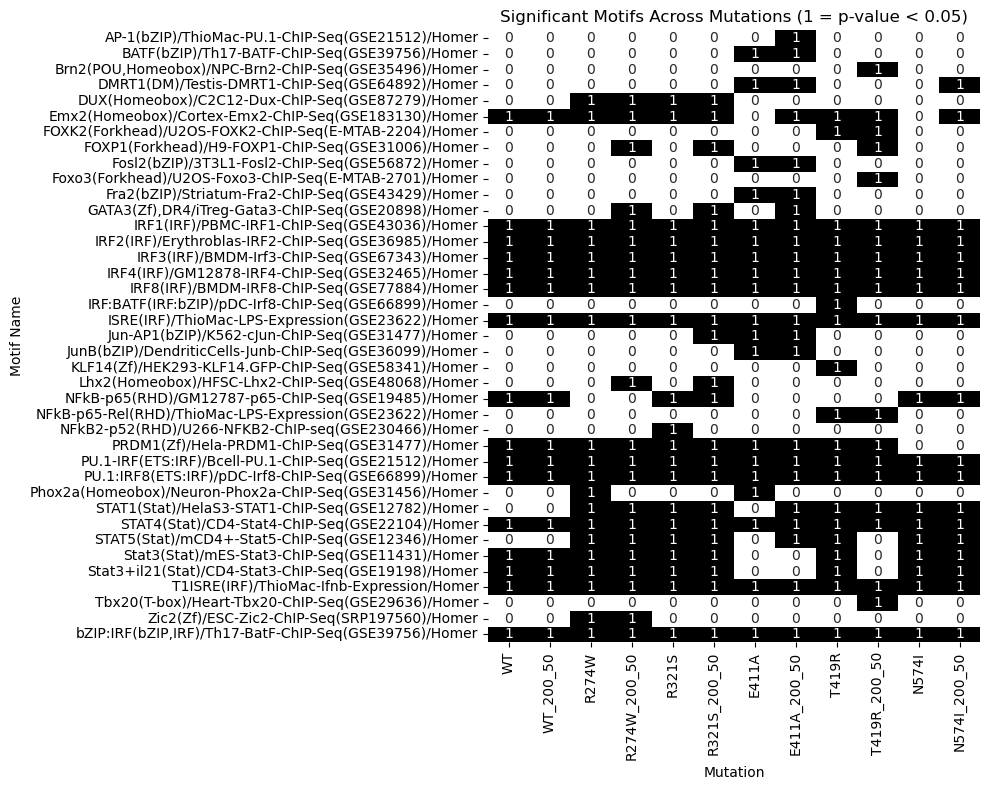

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(df_pivot_bool, annot=True, cmap='binary', cbar=False)
plt.title('Significant Motifs Across Mutations (1 = p-value < 0.05)')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

Filter out motifs that are significant in all mutations.

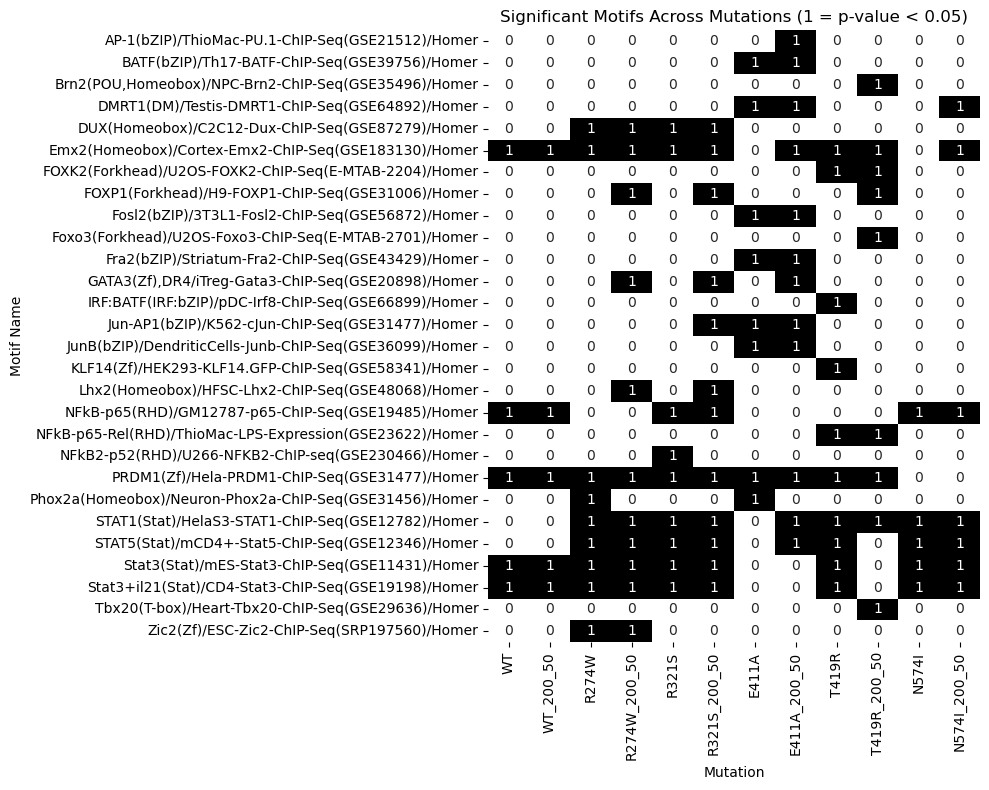

In [ ]:
df_pivot_filtered = df_pivot[df_pivot[df_pivot.columns].gt(0.05).any(axis=1)]
df_pivot_bool_filtered = df_pivot_filtered.copy()
df_pivot_bool_filtered[df_pivot.columns] = np.where(df_pivot_filtered[df_pivot.columns] < 0.05, 1, 0)

plt.figure(figsize=(10, 8))
sns.heatmap(df_pivot_bool_filtered, annot=True, cmap='binary', cbar=False)
plt.title('Significant Motifs Across Mutations (1 = p-value < 0.05)')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

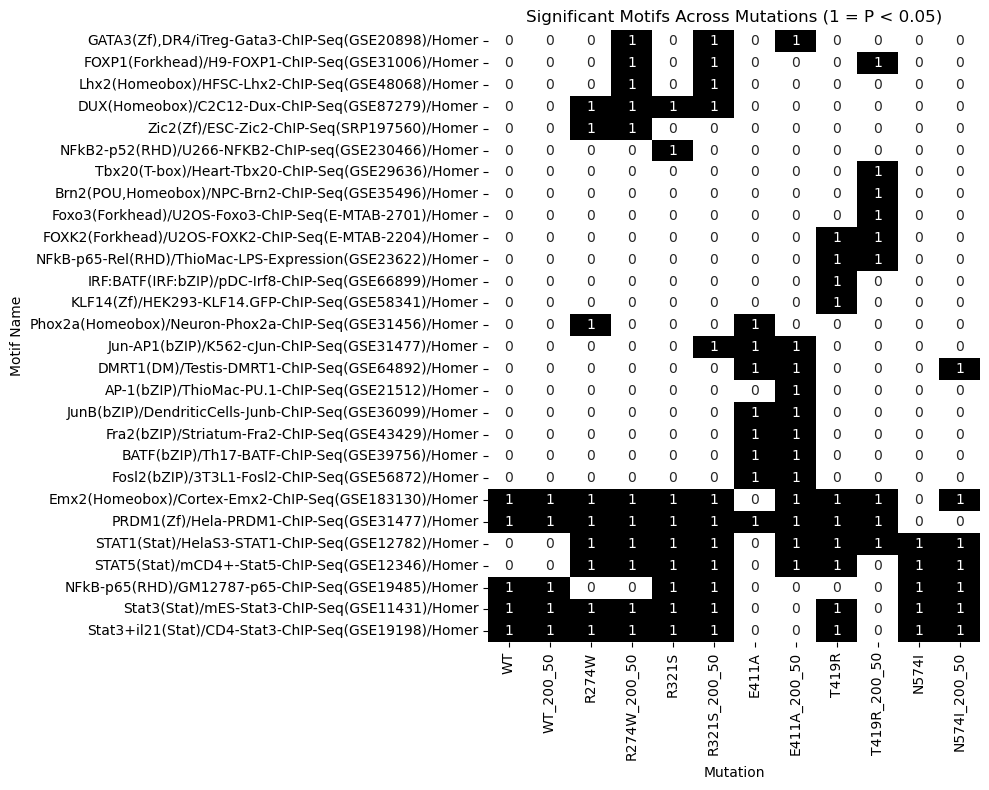

In [ ]:
linkage = hierarchy.linkage(df_pivot_bool_filtered, method='average', metric='euclidean')

row_order = hierarchy.leaves_list(linkage)

df_pivot_bool_reordered = df_pivot_bool_filtered.iloc[row_order]

# Plot the heatmap with reordered rows
plt.figure(figsize=(10, 8))
sns.heatmap(df_pivot_bool_reordered,  annot=True, cmap='binary', cbar=False)
plt.title('Significant Motifs Across Mutations (1 = P < 0.05)')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

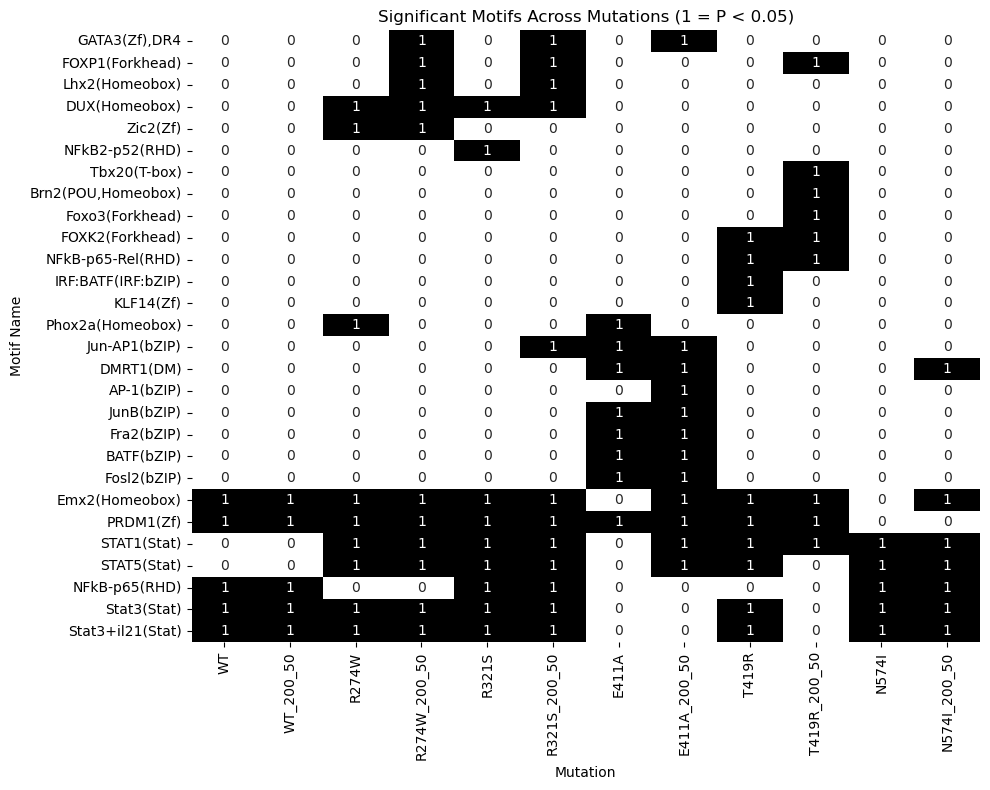

In [ ]:
linkage = hierarchy.linkage(df_pivot_bool_filtered, method='average', metric='euclidean')

row_order = hierarchy.leaves_list(linkage)

df_pivot_bool_reordered = df_pivot_bool_filtered.iloc[row_order]
df_pivot_bool_reordered.index = df_pivot_bool_reordered.index.map(lambda x: x.split("/",1)[0])

# Plot the heatmap with reordered rows
plt.figure(figsize=(10, 8))
sns.heatmap(df_pivot_bool_reordered,  annot=True, cmap='binary', cbar=False)
plt.title('Significant Motifs Across Mutations (1 = P < 0.05)')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

Applying hierarchical clustering order to both rows (as in the previous plot) and columns, and displaying the dendrogram.

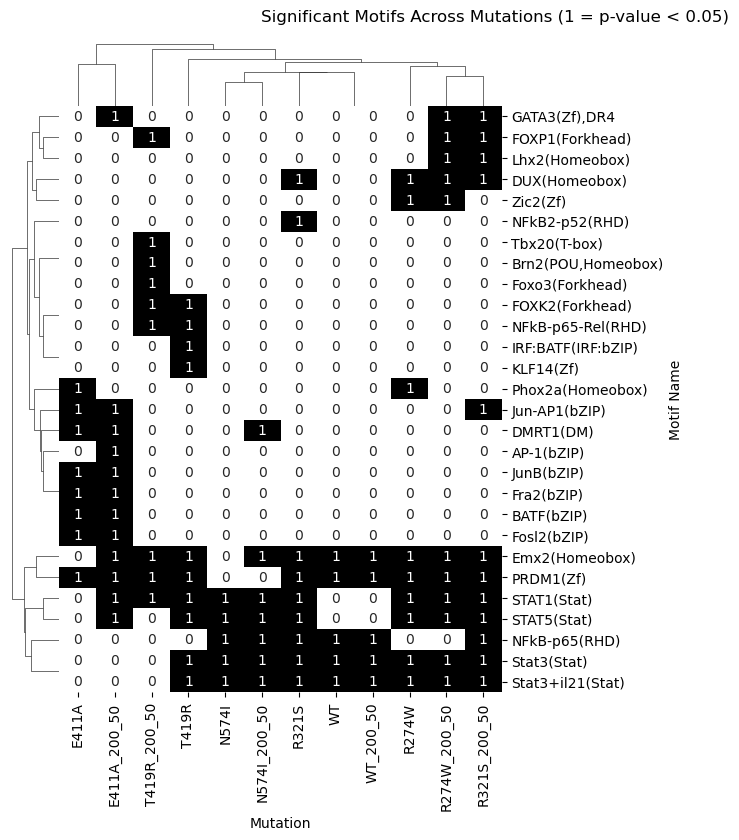

In [ ]:
g = sns.clustermap(
    df_pivot_bool_filtered,
    method='average',
    metric='euclidean',
    cmap='binary',
    annot=True,
    cbar=False,
    cbar_pos=None,
    dendrogram_ratio=0.1,
    figsize=(10, 8)
)

# Update motif names in the index
g.ax_heatmap.set_yticklabels([label.get_text().split("/", 1)[0] for label in g.ax_heatmap.get_yticklabels()])
g.figure.suptitle('Significant Motifs Across Mutations (1 = p-value < 0.05)', y=1.02)  # Adjust y for positioning
g.ax_heatmap.set_xlabel('Mutation')
g.ax_heatmap.set_ylabel('Motif Name')

plt.show()

#### Target gene %

In [ ]:
comparison.columns

Index(['Motif Name', 'Consensus_WT', 'P-value_WT', 'Log P-value_WT',
       'q-value (Benjamini)_WT', '# of Target Sequences with Motif(of 46)_WT',
       '% of Target Sequences with Motif_WT',
       '# of Background Sequences with Motif(of 43551)',
       '% of Background Sequences with Motif_WT', 'Consensus_WT_200_50',
       'P-value_WT_200_50', 'Log P-value_WT_200_50',
       'q-value (Benjamini)_WT_200_50',
       '# of Target Sequences with Motif(of 46)_WT_200_50',
       '% of Target Sequences with Motif_WT_200_50',
       '# of Background Sequences with Motif(of 42368)',
       '% of Background Sequences with Motif_WT_200_50', 'Consensus_R274W',
       'P-value_R274W', 'Log P-value_R274W', 'q-value (Benjamini)_R274W',
       '# of Target Sequences with Motif(of 121)_R274W',
       '% of Target Sequences with Motif_R274W',
       '# of Background Sequences with Motif(of 45218)',
       '% of Background Sequences with Motif_R274W', 'Consensus_R274W_200_50',
       'P-value_R274W

In [ ]:
target_cols = [col for col in comparison.columns if col.startswith('% of Target Sequences with Motif_')]
df_targetpercent = comparison[['Motif Name'] + target_cols].copy()

In [ ]:
df_targetpercent = df_targetpercent.map(lambda x: float(x.replace('%', '')) if isinstance(x, str) and '%' in x else x)

In [ ]:
df_targetpercent.head()

,Motif Name,% of Target Sequences with Motif_WT,% of Target Sequences with Motif_WT_200_50,% of Target Sequences with Motif_R274W,% of Target Sequences with Motif_R274W_200_50,% of Target Sequences with Motif_R321S,% of Target Sequences with Motif_R321S_200_50,% of Target Sequences with Motif_E411A,% of Target Sequences with Motif_E411A_200_50,% of Target Sequences with Motif_T419R,% of Target Sequences with Motif_T419R_200_50,% of Target Sequences with Motif_N574I,% of Target Sequences with Motif_N574I_200_50
0,AMYB(HTH)/Testes-AMYB-ChIP-Seq(GSE44588)/Homer,15.22,10.87,19.01,14.05,19.23,16.92,19.05,18.25,19.75,16.56,19.25,16.77
1,AP-1(bZIP)/ThioMac-PU.1-ChIP-Seq(GSE21512)/Homer,19.57,15.22,10.74,9.09,12.31,10.00,12.70,11.11,8.92,7.01,11.18,8.70
2,AP-2alpha(AP2)/Hela-AP2alpha-ChIP-Seq(GSE31477...,23.91,19.57,25.62,17.36,21.54,15.38,22.22,16.67,20.38,15.29,20.50,14.91
3,AP-2gamma(AP2)/MCF7-TFAP2C-ChIP-Seq(GSE21234)/...,26.09,21.74,30.58,22.31,26.92,20.00,27.78,22.22,26.11,21.02,24.84,18.63
4,AR-halfsite(NR)/LNCaP-AR-ChIP-Seq(GSE27824)/Homer,54.35,50.00,38.84,32.23,37.69,31.54,41.27,34.13,44.59,36.31,42.24,35.40


In [ ]:
df_targetpercent["Motif Name"] = df_targetpercent["Motif Name"].map(lambda x: x.split("/")[:1])
df_targetpercent["Motif Name"] = df_targetpercent["Motif Name"].apply(lambda x: "/".join(map(str, x)))

In [ ]:
df_targetpercent.head()

,Motif Name,% of Target Sequences with Motif_WT,% of Target Sequences with Motif_WT_200_50,% of Target Sequences with Motif_R274W,% of Target Sequences with Motif_R274W_200_50,% of Target Sequences with Motif_R321S,% of Target Sequences with Motif_R321S_200_50,% of Target Sequences with Motif_E411A,% of Target Sequences with Motif_E411A_200_50,% of Target Sequences with Motif_T419R,% of Target Sequences with Motif_T419R_200_50,% of Target Sequences with Motif_N574I,% of Target Sequences with Motif_N574I_200_50
0,AMYB(HTH),15.22,10.87,19.01,14.05,19.23,16.92,19.05,18.25,19.75,16.56,19.25,16.77
1,AP-1(bZIP),19.57,15.22,10.74,9.09,12.31,10.00,12.70,11.11,8.92,7.01,11.18,8.70
2,AP-2alpha(AP2),23.91,19.57,25.62,17.36,21.54,15.38,22.22,16.67,20.38,15.29,20.50,14.91
3,AP-2gamma(AP2),26.09,21.74,30.58,22.31,26.92,20.00,27.78,22.22,26.11,21.02,24.84,18.63
4,AR-halfsite(NR),54.35,50.00,38.84,32.23,37.69,31.54,41.27,34.13,44.59,36.31,42.24,35.40


In [ ]:
# Extract mutation names from column names
df_targetpercent.columns = ['Motif Name'] + [col.replace('% of Target Sequences with Motif_', '') for col in df_targetpercent.columns if col.startswith('% of Target Sequences with Motif_')]
df_target_pivot = df_targetpercent.set_index('Motif Name')
df_target_pivot.head()

,WT,WT_200_50,R274W,R274W_200_50,R321S,R321S_200_50,E411A,E411A_200_50,T419R,T419R_200_50,N574I,N574I_200_50
Motif Name,,,,,,,,,,,,
AMYB(HTH),15.22,10.87,19.01,14.05,19.23,16.92,19.05,18.25,19.75,16.56,19.25,16.77
AP-1(bZIP),19.57,15.22,10.74,9.09,12.31,10.00,12.70,11.11,8.92,7.01,11.18,8.70
AP-2alpha(AP2),23.91,19.57,25.62,17.36,21.54,15.38,22.22,16.67,20.38,15.29,20.50,14.91
AP-2gamma(AP2),26.09,21.74,30.58,22.31,26.92,20.00,27.78,22.22,26.11,21.02,24.84,18.63
AR-halfsite(NR),54.35,50.00,38.84,32.23,37.69,31.54,41.27,34.13,44.59,36.31,42.24,35.40


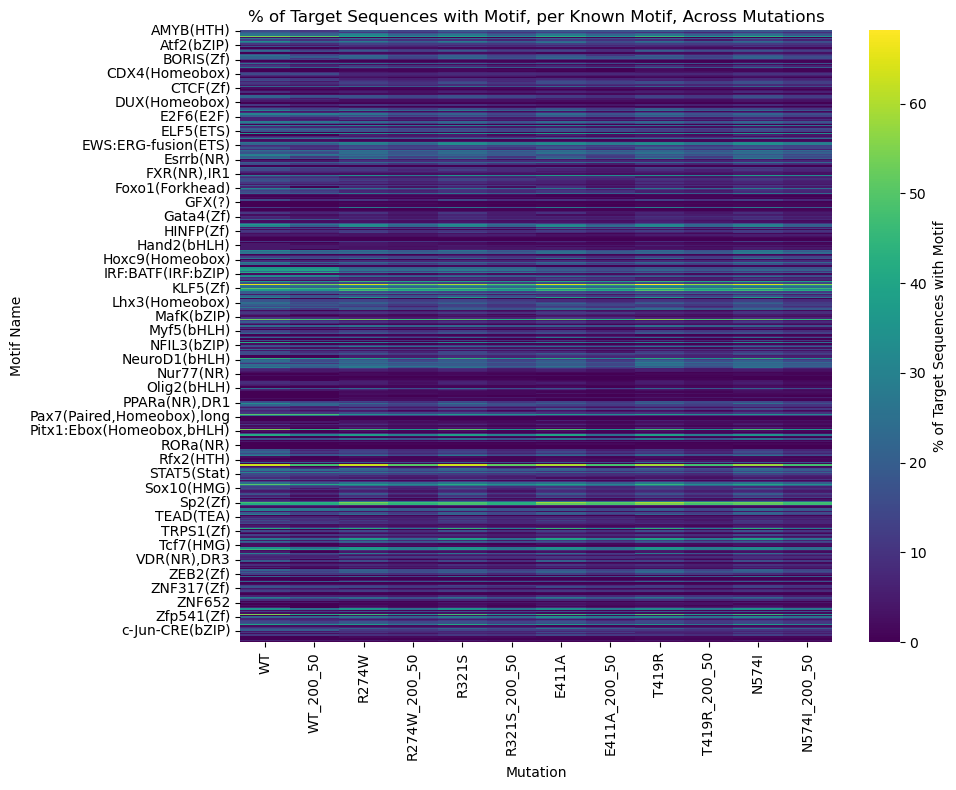

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(df_target_pivot, cmap='viridis', cbar_kws={'label': '% of Target Sequences with Motif'})
plt.title('% of Target Sequences with Motif, per Known Motif, Across Mutations')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()



In [ ]:
n_motifs = df_target_pivot.shape[0]
height_per_motif = 0.25 
fig_height = max(8, n_motifs * height_per_motif)  # min height 8
fig_width = 10

g = sns.clustermap(
    df_target_pivot,
    method='average',
    metric='euclidean',
    cmap='viridis',
    cbar=True,
    cbar_pos=(0.90, 0.05, 0.03, 0.3),
    dendrogram_ratio=0.1,
    figsize=(fig_width, fig_height)
)

# Update motif names in the index
g.figure.suptitle('% of Target Sequences with Motif, per Known Motif, Across Mutations (Hierachical clustering)', y=1.02)
g.ax_heatmap.set_xlabel('Mutation')
g.ax_heatmap.set_ylabel('Motif Name')

plt.show()

**Filter by motifs with significant differences across mutations**

Show only the motifs that, as a result of the previous analysis, were found to be significant in some mutations and non-significant in others.

In [ ]:
motifs_sig = df_pivot_bool_filtered.index

In [ ]:
len(motifs_sig)

28

There are 28 motifs meeting this criteria.

Shorten the motif names.

In [ ]:
motifs_sig = motifs_sig.map(lambda x: x.split("/",1)[0])

In [ ]:
motifs_sig

Index(['AP-1(bZIP)', 'BATF(bZIP)', 'Brn2(POU,Homeobox)', 'DMRT1(DM)',
       'DUX(Homeobox)', 'Emx2(Homeobox)', 'FOXK2(Forkhead)', 'FOXP1(Forkhead)',
       'Fosl2(bZIP)', 'Foxo3(Forkhead)', 'Fra2(bZIP)', 'GATA3(Zf),DR4',
       'IRF:BATF(IRF:bZIP)', 'Jun-AP1(bZIP)', 'JunB(bZIP)', 'KLF14(Zf)',
       'Lhx2(Homeobox)', 'NFkB-p65(RHD)', 'NFkB-p65-Rel(RHD)',
       'NFkB2-p52(RHD)', 'PRDM1(Zf)', 'Phox2a(Homeobox)', 'STAT1(Stat)',
       'STAT5(Stat)', 'Stat3(Stat)', 'Stat3+il21(Stat)', 'Tbx20(T-box)',
       'Zic2(Zf)'],
      dtype='object', name='Motif Name')

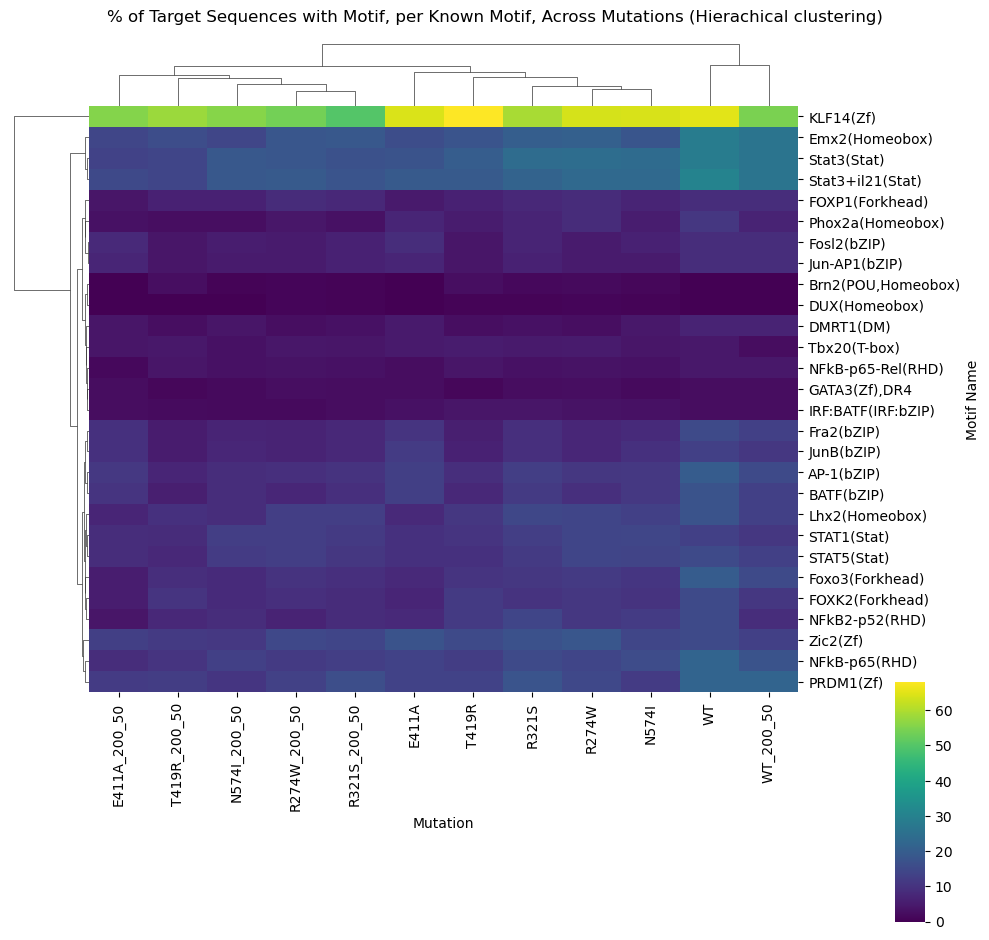

In [ ]:
g = sns.clustermap(
    df_target_pivot[df_target_pivot.index.isin(motifs_sig)],
    method='average',
    metric='euclidean',
    cmap='viridis',
    cbar=True,
    cbar_pos=(0.90, 0.-0.12, 0.03, 0.3),
    dendrogram_ratio=0.1,
    figsize=(10, 8)
)

# Update motif names in the index
g.figure.suptitle('% of Target Sequences with Motif, per Known Motif, Across Mutations (Hierachical clustering)', y=1.02)
g.ax_heatmap.set_xlabel('Mutation')
g.ax_heatmap.set_ylabel('Motif Name')

plt.show()

**Filter motifs by percentage**

Filter out motifs present in < 10 % of target sequences for all mutations and WT.

(This was a test, but the results are not very interesting.)

In [ ]:
df_targetpercent.shape

(471, 13)

In [ ]:
df_targetpercent.columns.difference(["Motif Name"])

Index(['E411A', 'E411A_200_50', 'N574I', 'N574I_200_50', 'R274W',
       'R274W_200_50', 'R321S', 'R321S_200_50', 'T419R', 'T419R_200_50', 'WT',
       'WT_200_50'],
      dtype='object')

In [ ]:
df_targetpercent_filtered = df_targetpercent[df_targetpercent[df_targetpercent.columns.difference(["Motif Name"])].astype(float).le(10).any(axis=1)]

In [ ]:
df_targetpercent_filtered.shape

(339, 13)

In [ ]:
df_target_filtered_pivot = df_targetpercent_filtered.set_index('Motif Name')

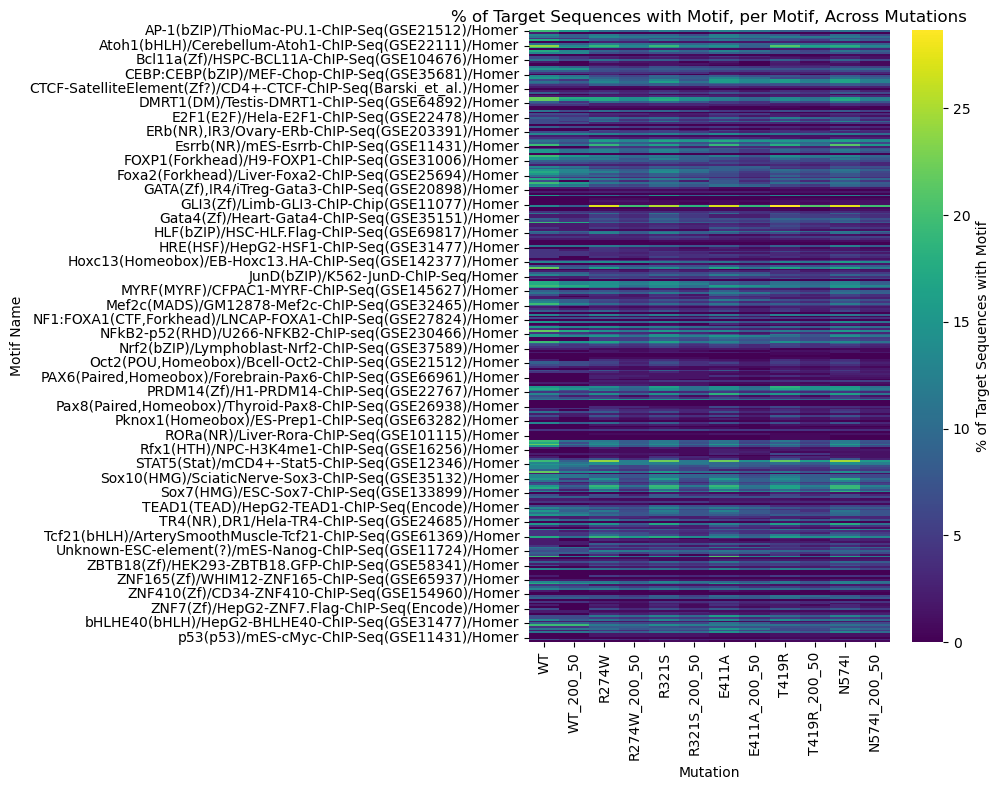

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(df_target_filtered_pivot, cmap='viridis', cbar_kws={'label': '% of Target Sequences with Motif'})
plt.title('% of Target Sequences with Motif, per Motif, Across Mutations')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

### De novo significant motifs

HOMER seems to mark as "possible false possitive" the de novo motifs with p-value >= 1e-11.

In [ ]:
def parse_denovo_motifs(file_path):
    # Initialize lists to store parsed data
    data = {
        'Consensus': [],
        'Motif_Name': [],
        'Best_Guess': [],
        'Score': [],
        'Log_Pvalue': [],
        'Qvalue': [],
        'Target_Percent': [],
        'Background_Percent': [],
        'Pvalue': []
    }
    
    # Read the file
    with open(file_path, 'r') as f:
        for line in f:
            if line.startswith('>'):
                # Split the header line
                parts = line.strip().split('\t')
                if len(parts) < 6:
                    continue  # Skip malformed lines
                
                # Extract fields
                consensus = parts[0][1:]  # Remove '>'
                motif_info = parts[1].split(',')
                motif_name = motif_info[0]
                best_guess = motif_info[1].replace("BestGuess:", "") if len(motif_info) > 1 else 'Unknown'
                score = float(parts[2])
                log_pvalue = float(parts[3])
                qvalue = float(parts[4])
                
                # Parse target and background stats
                stats = parts[5].split(',')
                target_info = stats[0].split(':')[1].split('(')
                target_count = float(target_info[0])
                target_percent = float(target_info[1].rstrip('%)'))
                bg_info = stats[1].split(':')[1].split('(')
                bg_count = float(bg_info[0])
                bg_percent = float(bg_info[1].rstrip('%)'))
                pvalue = parts[5].split('P:')[1]
                
                # Append to data
                data['Consensus'].append(consensus)
                data['Motif_Name'].append(motif_name)
                data['Best_Guess'].append(best_guess)
                data['Score'].append(score)
                data['Log_Pvalue'].append(log_pvalue)
                data['Qvalue'].append(qvalue)
                data['Target_Percent'].append(target_percent)
                data['Background_Percent'].append(bg_percent)
                data['Pvalue'].append(pvalue)
    
    # Create DataFrame
    df = pd.DataFrame(data)
    return df

In [ ]:
novo_motif_dfs = {}

for col in up_cols:
    key_motifs = f"{col}_motifs"
    key_motifs_200_50 = f"{col}_motifs_200_50"

    print(key_motifs)
    novo_motif_dfs[key_motifs] = parse_denovo_motifs(f"up_{col}/nonRedundant.motifs")
    print(novo_motif_dfs[key_motifs].shape)
    
    print(key_motifs_200_50)
    novo_motif_dfs[key_motifs_200_50] = parse_denovo_motifs(f"up_{col}_200_50/nonRedundant.motifs")
    print(novo_motif_dfs[key_motifs_200_50].shape)

WT_motifs
(16, 9)
WT_motifs_200_50
(12, 9)
R274W_motifs
(18, 9)
R274W_motifs_200_50
(16, 9)
R321S_motifs
(34, 9)
R321S_motifs_200_50
(13, 9)
E411A_motifs
(40, 9)
E411A_motifs_200_50
(16, 9)
T419R_motifs
(18, 9)
T419R_motifs_200_50
(28, 9)
N574I_motifs
(40, 9)
N574I_motifs_200_50
(14, 9)


In [ ]:
novo_motif_dfs["WT_motifs"].head()


,Consensus,Motif_Name,Best_Guess,Score,Log_Pvalue,Qvalue,Target_Percent,Background_Percent,Pvalue
0,GAAACTGAAA,1-GAAACTGAAA,Irf1/MA0050.4/Jaspar(0.981),10.295289,-38.312700,0.0,36.96,2.05,1e-16
1,ACACCCTC,1-ACACCCTC,EKLF(Zf)/Erythrocyte-Klf1-ChIP-Seq(GSE20478)/H...,7.419771,-27.502651,0.0,47.83,8.09,1e-11
2,CGGRTGTCTGGT,2-CGGRTGTCTGGT,PB0060.1_Smad3_1/Jaspar(0.723),8.895358,-23.545279,0.0,26.09,1.93,1e-10
3,CTGSASCTCTAA,3-CTGSASCTCTAA,ZNF135/MA1587.1/Jaspar(0.592),10.310263,-23.472361,0.0,13.04,0.13,1e-10
4,CACCAGTTTT,3-CACCAGTTTT,GRHL1/MA0647.2/Jaspar(0.652),11.068204,-23.368651,0.0,17.39,0.48,1e-10


In [ ]:
df_pivot.columns

Index(['WT', 'WT_200_50', 'R274W', 'R274W_200_50', 'R321S', 'R321S_200_50',
       'E411A', 'E411A_200_50', 'T419R', 'T419R_200_50', 'N574I',
       'N574I_200_50'],
      dtype='object')

In [ ]:
# Initialize an empty list to collect data
motif_pvalues = []

# Get unique motifs and collect P-values
for df_name in novo_motif_dfs.keys():
    # Convert Pvalue to numeric, handling scientific notation
    novo_motif_dfs[df_name]["Pvalue"] = pd.to_numeric(novo_motif_dfs[df_name]["Pvalue"])
    novo_motif_dfs[df_name]["Pvalue"] = np.where(novo_motif_dfs[df_name]["Pvalue"] < 1e-11, 1, 0)
    # Ensure the column contains only strings before applying .str
    novo_motif_dfs[df_name]["Best_Guess"] = novo_motif_dfs[df_name]["Best_Guess"].str.split("/").str[:2]
    novo_motif_dfs[df_name]["Best_Guess"] = novo_motif_dfs[df_name]["Best_Guess"].apply(lambda x: "/".join(map(str, x)))
    
    # Filter for significant motifs (P-value < 1e-11)
    filtered_df = novo_motif_dfs[df_name][["Best_Guess", "Pvalue"]].drop_duplicates()
    # Rename Pvalue column to the DataFrame name
    filtered_df = filtered_df.rename(columns={"Pvalue": df_name})
    filtered_df.columns = filtered_df.columns.str.replace('_motifs', '')
    
    # Append to list
    motif_pvalues.append(filtered_df)

# Merge all DataFrames on Best_Guess using outer join
denovo_sig = motif_pvalues[0]
for df in motif_pvalues[1:]:
    denovo_sig = denovo_sig.merge(df, on="Best_Guess", how="outer")

# Set Best_Guess as index
denovo_sig = denovo_sig.set_index("Best_Guess")

denovo_sig.shape



(135, 12)

In [ ]:
denovo_sig.head(20)

,WT,WT_200_50,R274W,R274W_200_50,R321S,R321S_200_50,E411A,E411A_200_50,T419R,T419R_200_50,N574I,N574I_200_50
Best_Guess,,,,,,,,,,,,
AP-2alpha(AP2)/Hela-AP2alpha-ChIP-Seq(GSE31477),1.0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN
Ahr::Arnt/MA0006.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN
Arntl/MA0603.2,NaN,1.0,NaN,NaN,NaN,NaN,1.0,1.0,NaN,1.0,NaN,NaN
BARX1/MA0875.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN
BATF3/MA0835.3,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN
CEBP:AP1(bZIP)/ThioMac-CEBPb-ChIP-Seq(GSE21512),1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CREB3L1/MA0839.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
CREB3L4/MA1474.2,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN
Dlx2/MA0885.3,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,1.0,NaN,1.0,NaN


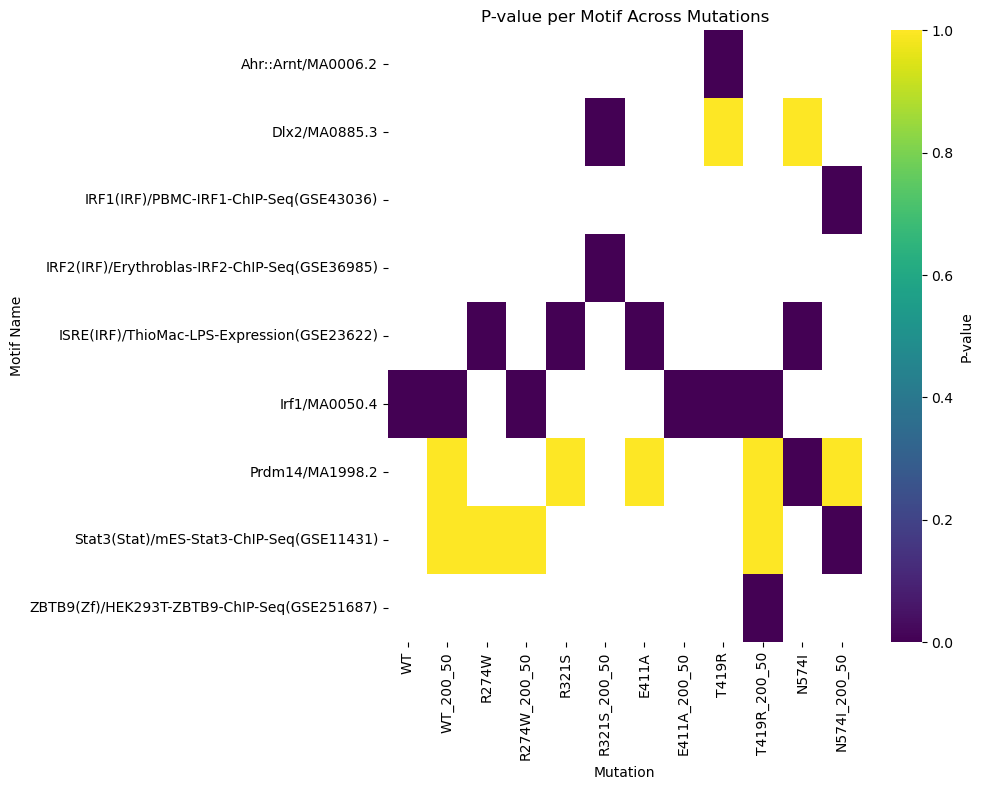

In [ ]:
denovo_sig_filtered = denovo_sig[denovo_sig[denovo_sig.columns].lt(1e-11).any(axis=1)]


plt.figure(figsize=(10, 8))
sns.heatmap(denovo_sig_filtered, cmap='viridis', cbar_kws={'label': 'P-value'})
plt.title('P-value per Motif Across Mutations')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

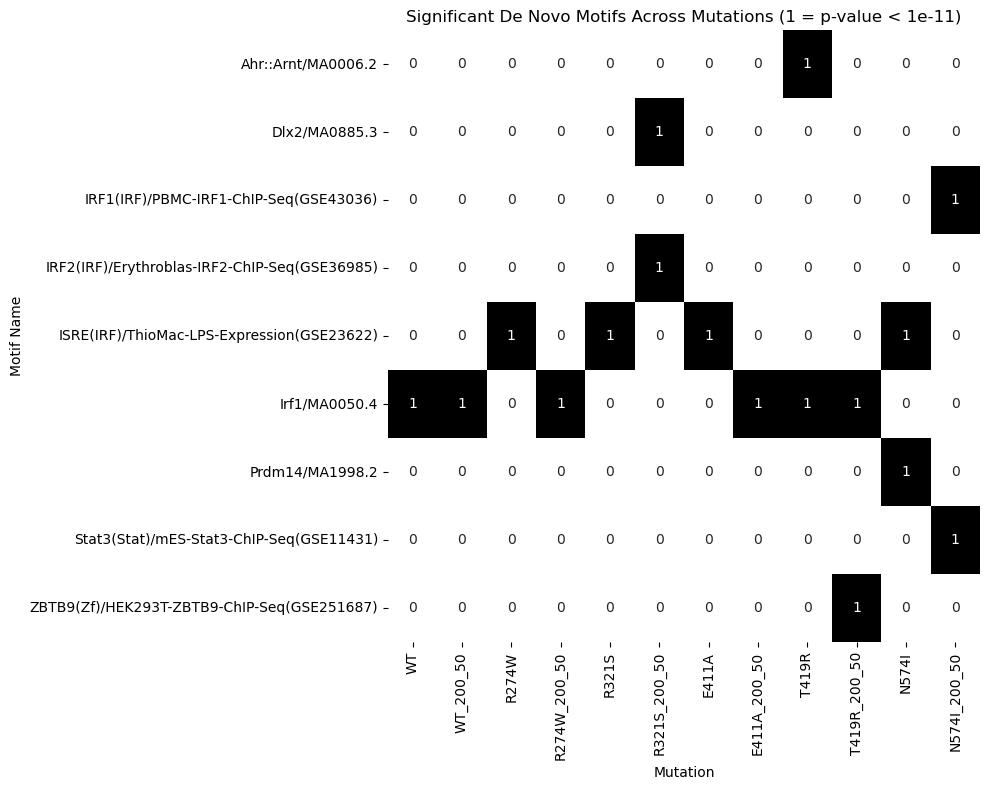

In [ ]:
denovo_sig_filtered_bool = denovo_sig_filtered.copy()
denovo_sig_filtered_bool[df_pivot.columns] = np.where(denovo_sig_filtered[df_pivot.columns] < 1e-11, 1, 0)

plt.figure(figsize=(10, 8))
sns.heatmap(denovo_sig_filtered_bool, annot=True, cmap='binary', cbar=False)
plt.title('Significant De Novo Motifs Across Mutations (1 = p-value < 1e-11)')
plt.xlabel('Mutation')
plt.ylabel('Motif Name')
plt.tight_layout()
plt.show()

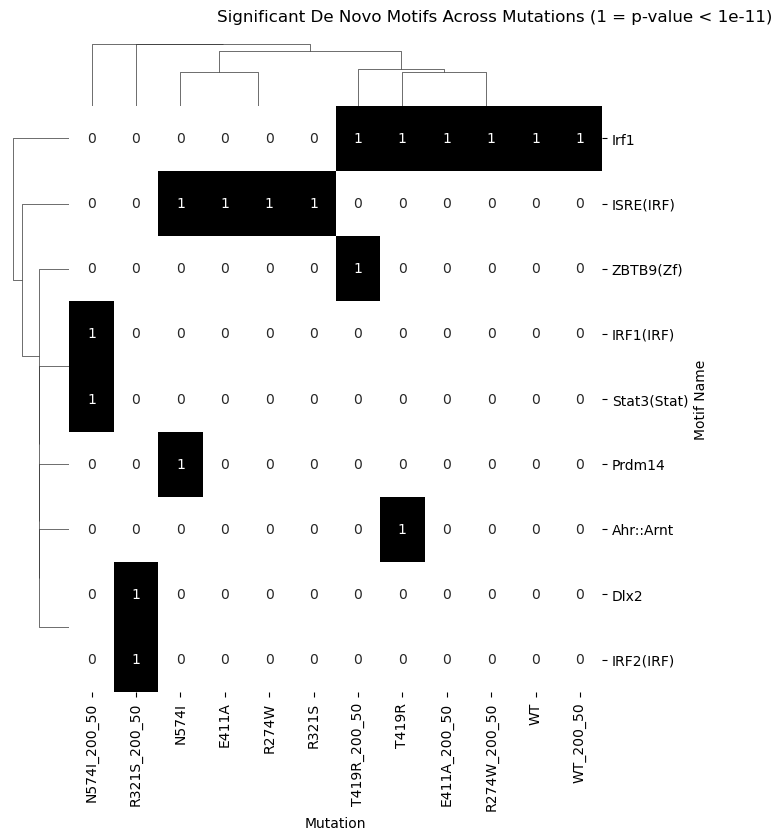

In [ ]:
g = sns.clustermap(
    denovo_sig_filtered_bool,
    method='average',
    metric='euclidean',
    cmap='binary',
    annot=True,
    cbar=False,
    cbar_pos=None,
    dendrogram_ratio=0.1,
    figsize=(10, 8)
)

# Update motif names in the index
g.ax_heatmap.set_yticklabels([label.get_text().split("/", 1)[0] for label in g.ax_heatmap.get_yticklabels()])
g.figure.suptitle('Significant De Novo Motifs Across Mutations (1 = p-value < 1e-11)', y=1.02)  # Adjust y for positioning
g.ax_heatmap.set_xlabel('Mutation')
g.ax_heatmap.set_ylabel('Motif Name')

plt.show()

In [107]:
combined_df_wt[combined_df_wt['donor_res_num_adjusted'] == 418]

,donor,hydrogen,acceptor,count,frame%,donor_res_name,donor_res_num,donor_atom_name,donor_chain,acceptor_res_name,acceptor_res_num,acceptor_atom_name,acceptor_chain,donor_type,acceptor_type,donor_res_num_adjusted,acceptor_res_num_adjusted,donor_section,acceptor_section
29,4735,4736,20156,20,1.998002,ARG,283,NE,A,DG,20,OP1,D,protein,DNA,418,20,DBD,backbone
30,4735,4736,20157,15,1.498501,ARG,283,NE,A,DG,20,OP2,D,protein,DNA,418,20,DBD,backbone
31,4738,4739,20124,1,0.099900,ARG,283,NH1,A,DT,19,OP1,D,protein,DNA,418,19,DBD,backbone
32,4738,4739,20156,2,0.199800,ARG,283,NH1,A,DG,20,OP1,D,protein,DNA,418,20,DBD,backbone
33,4738,4740,20124,38,3.796204,ARG,283,NH1,A,DT,19,OP1,D,protein,DNA,418,19,DBD,backbone
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
160,14154,14155,19773,16,1.598402,ARG,283,NH2,B,DT,7,O3',D,protein,DNA,418,7,DBD,backbone
161,14154,14155,19775,17,1.698302,ARG,283,NH2,B,DT,8,OP1,D,protein,DNA,418,8,DBD,backbone
162,14154,14156,19388,261,26.073926,ARG,283,NH2,B,DT,18,O2,C,protein,DNA,418,18,DBD,base
163,14154,14156,19420,2,0.199800,ARG,283,NH2,B,DG,19,N3,C,protein,DNA,418,19,DBD,base


### Protein as acceptor

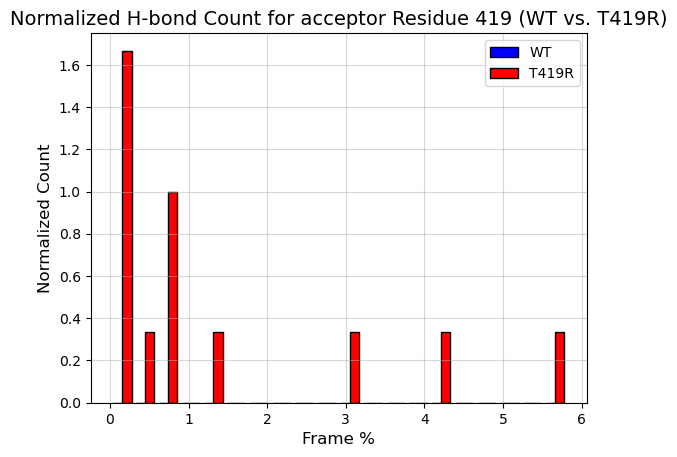

In [638]:
# Filter data
filtered_df_T419R = combined_df_T419R[combined_df_T419R['acceptor_res_num_adjusted'] == 419]
filtered_df_wt = combined_df_wt[combined_df_wt['acceptor_res_num_adjusted'] == 419]

# Common bins
bins = np.histogram(np.hstack((filtered_df_wt['frame%'], filtered_df_T419R['frame%'])), bins=20)[1]
wt_counts, wt_bins = np.histogram(filtered_df_wt['frame%'], bins=bins)
mut_counts, mut_bins = np.histogram(filtered_df_T419R['frame%'], bins=bins)

# Normalize WT counts by the number of replicates
normalized_wt_counts = wt_counts / len(wt_dfs)
normalizad_mut_counts = mut_counts / len(T419R_dfs)

# Bar positions
bar_width = (bins[1] - bins[0]) * 0.4
wt_positions = bins[:-1]
mut_positions = bins[:-1] + bar_width

# Plot
plt.bar(wt_positions, normalized_wt_counts, width=bar_width, color='blue', label='WT', edgecolor='black')
plt.bar(mut_positions, normalizad_mut_counts, width=bar_width, color='red', label='T419R', edgecolor='black')

# Customize
plt.xlabel('Frame %', fontsize=12)
plt.ylabel('Normalized Count', fontsize=12)  # Updated y-axis label
plt.title('Normalized H-bond Count for acceptor Residue 419 (WT vs. T419R)', fontsize=14)  # Updated title
#plt.xticks(np.arange(10, 101, 10))  # Ticks every 10%, starting from 10
plt.legend(fontsize=10)
plt.grid(True, alpha=0.5)

plt.show()

In [639]:
filtered_df_T419R.sort_values('frame%', ascending=False)

,donor,hydrogen,acceptor,count,frame%,donor_res_name,donor_res_num,donor_atom_name,donor_chain,acceptor_res_name,acceptor_res_num,acceptor_atom_name,acceptor_chain,donor_type,acceptor_type,donor_res_num_adjusted,acceptor_res_num_adjusted,donor_section,acceptor_section
218,20197,20199,4762,59,5.894106,DG,20,N2,D,ARG,284,NH1,A,DNA,protein,20,419,base,DBD
211,20197,20199,4765,42,4.195804,DG,20,N2,D,ARG,284,NH2,A,DNA,protein,20,419,base,DBD
198,19024,19026,4762,31,3.096903,DG,6,N2,C,ARG,284,NH1,A,DNA,protein,6,419,base,DBD
215,19437,19439,14188,15,1.498501,DG,19,N2,C,ARG,284,NH2,B,DNA,protein,19,419,base,DBD
226,20197,20199,4762,9,0.899101,DG,20,N2,D,ARG,284,NH1,A,DNA,protein,20,419,base,DBD
212,19024,19026,4765,9,0.899101,DG,6,N2,C,ARG,284,NH2,A,DNA,protein,6,419,base,DBD
209,20197,20199,4765,8,0.799201,DG,20,N2,D,ARG,284,NH2,A,DNA,protein,20,419,base,DBD
209,20197,20199,4759,6,0.599401,DG,20,N2,D,ARG,284,NE,A,DNA,protein,20,419,base,DBD
204,19024,19026,4762,2,0.199800,DG,6,N2,C,ARG,284,NH1,A,DNA,protein,6,419,base,DBD
208,20197,20199,4759,1,0.099900,DG,20,N2,D,ARG,284,NE,A,DNA,protein,20,419,base,DBD


In [640]:
filtered_df_wt.sort_values('frame%', ascending=False)

,donor,hydrogen,acceptor,count,frame%,donor_res_name,donor_res_num,donor_atom_name,donor_chain,acceptor_res_name,acceptor_res_num,acceptor_atom_name,acceptor_chain,donor_type,acceptor_type,donor_res_num_adjusted,acceptor_res_num_adjusted,donor_section,acceptor_section


WT does not form any hydrogen bonds with residue 419 as the acceptor, while T419R does, albeit with low frame %.

### Statistical test (Mann-Whitney)

In [602]:
from scipy.stats import mannwhitneyu, ttest_ind

In [603]:
# Aggregate hbond counts for each unique hbond across replicates or methods
def aggregate_hbonds(df_list, label):
    combined = pd.concat(df_list)
    agg_df = combined.groupby(['donor', 'acceptor', 'donor_res_num_adjusted', 
                               'acceptor_res_num_adjusted'])['count'].sum().reset_index()
    agg_df['group'] = label
    return agg_df

wt_agg = aggregate_hbonds(wt_dfs_flat, 'wt')
mut_agg = aggregate_hbonds(T419R_dfs_flat, 'T419R')

# Merge WT and MUT aggregated data
all_hbonds = pd.concat([wt_agg, mut_agg])

In [604]:
all_hbonds.head()

,donor,acceptor,donor_res_num_adjusted,acceptor_res_num_adjusted,count,group
0,3216,19869,327,11,30,wt
1,3216,19870,327,11,553,wt
2,3216,19871,327,11,2,wt
3,3216,19897,327,11,5,wt
4,3216,19899,327,12,195,wt


In [605]:
# Pivot table to compare WT and MUT (unchanged)
pivot_df = all_hbonds.pivot_table(index=['donor', 'acceptor', 'donor_res_num_adjusted', 
                               'acceptor_res_num_adjusted'], 
                                  columns='group', values='count', fill_value=0)
pivot_df['diff'] = pivot_df['T419R'] - pivot_df['wt']

# Aggregate WT counts across replicates
wt_counts_by_rep = [df.groupby(['donor', 'acceptor', 'donor_res_num_adjusted', 
                               'acceptor_res_num_adjusted'])['count'].sum() for df in wt_dfs_flat]
wt_counts_df = pd.concat(wt_counts_by_rep, axis=1).fillna(0)
wt_counts_df.columns = [f'rep{i+1}' for i in range(len(wt_dfs_flat))]
wt_mean = wt_counts_df.mean(axis=1)
wt_std = wt_counts_df.std(axis=1)

# Aggregate MUT counts
mut_counts = mut_agg.groupby(['donor', 'acceptor', 'donor_res_num_adjusted', 
                               'acceptor_res_num_adjusted'])['count'].sum()

# Create a common index to avoid KeyErrors
common_index = wt_counts_df.index.union(mut_counts.index)

# Reindex both WT and MUT data to the common index
wt_counts_df = wt_counts_df.reindex(common_index, fill_value=0)
wt_mean = wt_counts_df.mean(axis=1)
wt_std = wt_counts_df.std(axis=1)
mut_counts = mut_counts.reindex(common_index, fill_value=0)

# Build comparison DataFrame
comparison_df = pd.DataFrame({
    'WT_mean': wt_mean,
    'WT_std': wt_std,
    'MUT': mut_counts
}).fillna(0)

# Modified compare_groups function to handle missing indices
def compare_groups(row):
    hbond_idx = row.name  # Multi-index tuple
    if hbond_idx in wt_counts_df.index:
        wt_vals = wt_counts_df.loc[hbond_idx].values  # Values across replicates
    else:
        wt_vals = np.zeros(4)  # If hbond not in WT, assume zero counts
    mut_val = row['MUT']
    if np.all(wt_vals == 0) and mut_val == 0:
        return np.nan
    # Use Mann-Whitney U test
    stat, pval = mannwhitneyu(wt_vals, [mut_val] * 4, alternative='two-sided')
    return pval

# Apply statistical test
comparison_df['p_value'] = comparison_df.apply(compare_groups, axis=1)

# Filter for significant differences
#significant_diff = comparison_df[comparison_df['p_value'] < 0.05]
significant_diff = comparison_df
print("Significant differences between WT and MUT:")

Significant differences between WT and MUT:


In [606]:
# Apply the compare_groups function to each row
comparison_df['p_value'] = comparison_df.apply(compare_groups, axis=1)

# Filter for significant differences (p-value < 0.05)
significant_diff = comparison_df[comparison_df['p_value'] < 0.05]

In [607]:
significant_diff.shape

(389, 4)

In [608]:
significant_diff.head(20)

WT_mean  \
donor acceptor donor_res_num_adjusted acceptor_res_num_adjusted               
3216  19889    327                    11                           0.000000   
      19890    327                    11                           0.000000   
      19919    327                    12                           0.000000   
      19920    327                    12                           0.000000   
3231  19889    328                    11                           0.000000   
      19890    328                    11                           0.000000   
      19891    328                    11                           0.000000   
      19900    328                    12                          18.833333   
      19919    328                    12                           0.000000   
      19920    328                    12                           0.000000   
3263  19920    330                    12                           0.000000   
3376  19889    336                    11                           0.000000   
      19890    336                    11                           0.000000   
      19919    336                    12                           0.000000   
      19920    336                    12                           0.000000   
      19966    336                    13                           0.000000   
      19969    336                    13                           0.000000   
      20002    336                    14                           0.000000   
3431  19869    340                    11                         256.500000   
      19870    340                    11                          30.833333   

                                                                     WT_std  \
donor acceptor donor_res_num_adjusted acceptor_res_num_adjusted               
3216  19889    327                    11                           0.000000   
      19890    327                    11                           0.000000   
      19919    327                    12                           0.000000   
      19920    327                    12                           0.000000   
3231  19889    328                    11                           0.000000   
      19890    328                    11                           0.000000   
      19891    328                    11                           0.000000   
      19900    328                    12                          14.005951   
      19919    328                    12                           0.000000   
      19920    328                    12                           0.000000   
3263  19920    330                    12                           0.000000   
3376  19889    336                    11                           0.000000   
      19890    336                    11                           0.000000   
      19919    336                    12                           0.000000   
      19920    336                    12                           0.000000   
      19966    336                    13                           0.000000   
      19969    336                    13                           0.000000   
      20002    336                    14                           0.000000   
3431  19869    340                    11                         393.377046   
      19870    340                    11                          21.008728   

                                                                 MUT   p_value  
donor acceptor donor_res_num_adjusted acceptor_res_num_adjusted                 
3216  19889    327                    11                          12  0.004040  
      19890    327                    11                           3  0.004040  
      19919    327                    12                          55  0.004040  
      19920    327                    12                          11  0.004040  
3231  19889    328                    11                         203  0.004040  
      19890    328     

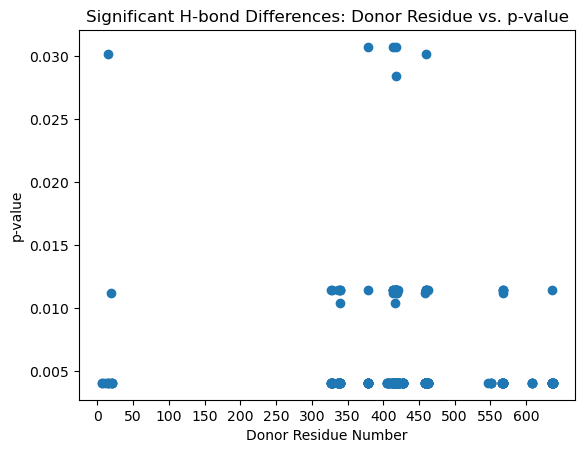

In [609]:
# Extract donor_res_num_adjusted from the multi-index
donor_res_nums = significant_diff.index.get_level_values('donor_res_num_adjusted')

# Plot donor_res_num_adjusted vs p_value
plt.plot(donor_res_nums, significant_diff['p_value'], 'o', label='Significant H-bonds')
# Set x-axis ticks every 5 residues
min_res = donor_res_nums.min()  # Minimum residue number
max_res = donor_res_nums.max()  # Maximum residue number
tick_locations = range(int(min_res // 50) * 50, int(max_res // 50) * 50 + 50, 50)  # Start at a multiple of 5, step by 5
plt.xticks(tick_locations)
plt.xlabel('Donor Residue Number')
plt.ylabel('p-value')
plt.title('Significant H-bond Differences: Donor Residue vs. p-value')
plt.show()

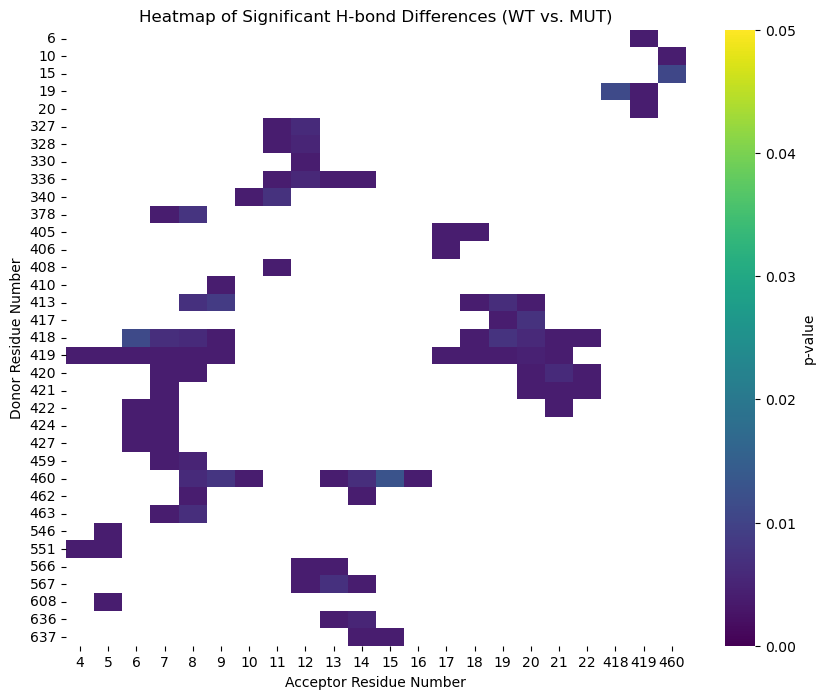

In [610]:
# Reset index to make donor_res_num_adjusted and acceptor_res_num_adjusted columns
significant_diff_reset = significant_diff.reset_index()

# Create a pivot table for the heatmap
heatmap_data = significant_diff_reset.pivot_table(
    index='donor_res_num_adjusted', 
    columns='acceptor_res_num_adjusted', 
    values='p_value', 
    #fill_value=1  # Use 1 (non-significant) for missing values
)

# Plot the heatmap
plt.figure(figsize=(10, 8))  # Adjust size as needed
sns.heatmap(
    heatmap_data, 
    cmap='viridis', 
    vmin=0, vmax=0.05,  # Focus on significant p-values 
    #annot=True, 
    fmt='.3f',  # Format annotations to 3 decimal places
    cbar_kws={'label': 'p-value'}  # Label the color bar
)

# Add labels and title
plt.xlabel('Acceptor Residue Number')
plt.ylabel('Donor Residue Number')
plt.title('Heatmap of Significant H-bond Differences (WT vs. MUT)')
plt.show()

In [611]:
significant_diff_reset[significant_diff_reset['donor_res_num_adjusted'] ==419].sort_values('p_value', ascending=False).head()

,donor,acceptor,donor_res_num_adjusted,acceptor_res_num_adjusted,WT_mean,WT_std,MUT,p_value
89,4756,20156,419,20,174.666667,190.323584,0,0.011153
86,4746,19034,419,6,0.000000,0.000000,1,0.004040
281,14185,19408,419,18,0.000000,0.000000,2546,0.004040
288,14185,19754,419,6,0.000000,0.000000,81,0.004040
287,14185,19440,419,19,0.000000,0.000000,78,0.004040


In [612]:
combined_df = pd.concat([wt_agg, mut_agg], ignore_index=True)

In [613]:
# Filter for residue 419
residue_419_df = combined_df[
    (combined_df['donor_res_num_adjusted'] == 419) | 
    (combined_df['acceptor_res_num_adjusted'] == 419)
]

In [614]:
# Separate WT and MUT data for residue 419
wt_419 = residue_419_df[residue_419_df['group'] == 'WT']
mut_419 = residue_419_df[residue_419_df['group'] == 'MUT']

# Perform statistical tests
t_stat, t_pval = ttest_ind(wt_419['count'], mut_419['count'], equal_var=False)
u_stat, u_pval = mannwhitneyu(wt_419['count'], mut_419['count'])

print(f"T-test p-value: {t_pval}")
print(f"Mann-Whitney U test p-value: {u_pval}")

T-test p-value: nan
Mann-Whitney U test p-value: nan


/home/irati/miniconda3/envs/thesis_md/lib/python3.12/site-packages/scipy/_lib/deprecation.py:234: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  return f(*args, **kwargs)
/tmp/ipykernel_1576982/2196208154.py:7: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  u_stat, u_pval = mannwhitneyu(wt_419['count'], mut_419['count'])


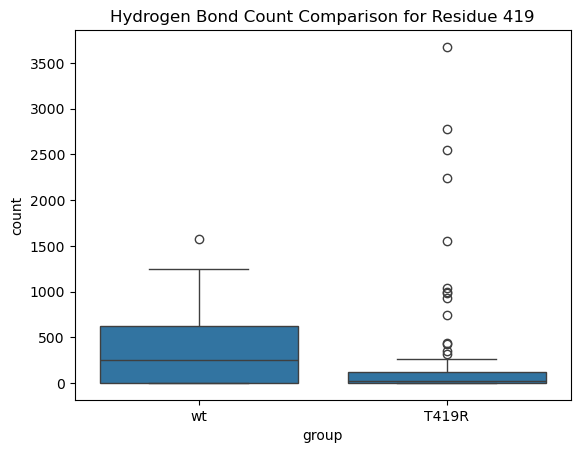

In [615]:
sns.boxplot(data=residue_419_df, x='group', y='count')
plt.title('Hydrogen Bond Count Comparison for Residue 419')
plt.show()